# Scientific Computing – First Lab
## Growth, biological maturation and physical performance in young athletes: a data-driven analysis in Python

**Student:** Ana María García Rodríguez
**Program:** Master in Automation and Industrial Control – Instituto Tecnológico Metropolitano (ITM)
**Course:** Scientific Computing – Prof. Sebastián Roldán Vasco
**Delivery date:** September 28, 2026

**How to run this notebook.** It is fully self-contained: the (anonymised) data are embedded in the notebook, and only three standard libraries are needed (`numpy`, `pandas`, `matplotlib`). In Google Colab or Jupyter simply choose *Run all*. Nothing is read from disk and no path has to be configured.

**Notebook map:** Context → Data loading and initial visualization → OOP for data processing → Numerical derivation or integration of data → Matrix operations → Discussion of results → Conclusions → AI Use Declaration.

# Context

### Research problem

Children of the same chronological age can be at very different stages of biological maturation. This matters in youth sport, because physical performance is related to biological maturation (Albaladejo-Saura et al., 2021), and talent selection tends to favour early maturers over late maturers, even when the difference in performance mainly reflects a difference in maturity and not in talent (Philippaerts et al., 2006).

Biological maturation can be assessed in several ways, for example through secondary sexual characteristics, skeletal age or anthropometric measures (Malina et al., 2015). Here we use the anthropometric approach. During puberty, growth in stature reaches a second maximum, the **peak height velocity (PHV)**, of roughly 8–10 cm per year (Kemper et al., 2023). PHV can be identified precisely only with a longitudinal follow-up of each child, which is rarely possible in field studies. For this reason Mirwald et al. (2002) proposed regression equations that predict the **maturity offset**, that is, the number of years a child is *before* (negative values) or *after* (positive values) PHV, using only sex, chronological age, stature, sitting height, leg length and body mass. An offset of 0 corresponds to PHV. The method reports an error of about ±6 months (Mirwald et al., 2002).

Around PHV, several physical capacities change quickly. In young soccer players, speed, jumping power and strength reached their best values close to PHV, whereas flexibility (sit-and-reach test) was the exception and peaked about 12 months later (Philippaerts et al., 2006). Muscle ultrasound adds structural information: for example, echo intensity is used as an indicator of skeletal muscle quality (Stock & Thompson, 2021).

### Data and aim of this lab

The data come from a cross-sectional study carried out in a research seedbed (*semillero*) in which I participated. It measured 184 children and adolescents (109 boys, 75 girls, 6.6–15.9 years old) of a youth sports school in Colombia: anthropometry, field tests of physical capacities and ultrasound of the rectus femoris. The research question of the seedbed is how physical capacities and muscle structure relate to biological maturation (PHV).

In this lab I use Python to build a small, reproducible analysis pipeline around that question:

1. load and describe the data and visualise a representative sample;
2. design an object-oriented pipeline (classes for the dataset, the maturity estimation and the numerical profiles);
3. apply **numerical differentiation** (growth velocity; rate of change of performance with maturity) and **numerical integration** (recovering height gain from velocity);
4. apply **matrix operations** (the Mirwald equations as a matrix product; correlation matrix, eigen-decomposition and principal components of the anthropometric and fitness variables).

### Computational background

*Numerical derivative.* For a function known at points $x_i$, the forward difference $f'(x_i)\approx \dfrac{f(x_{i+1})-f(x_i)}{x_{i+1}-x_i}$ has an error proportional to the step $h$, while the central difference $f'(x_i)\approx \dfrac{f(x_{i+1})-f(x_{i-1})}{x_{i+1}-x_{i-1}}$ has an error proportional to $h^2$. `numpy.gradient` implements the central scheme for unevenly spaced points.

*Numerical integral.* The trapezoidal rule approximates $\int_a^b f(x)\,dx \approx \sum_i \dfrac{f(x_i)+f(x_{i+1})}{2}\,(x_{i+1}-x_i)$.

*Matrix formulation.* If $D$ is a design matrix (one row per child, one column per predictor) and $\beta$ a vector of coefficients, the predictions are the matrix product $\hat y = D\beta$. This is exactly the form of the Mirwald equations.

*Software.* Everything is done in Python with NumPy (Harris et al., 2020), pandas (McKinney, 2010) and Matplotlib (Hunter, 2007).

*Principal component analysis (PCA).* For a standardised data matrix $Z$ ($n \times p$), the correlation matrix is $C = \dfrac{1}{n-1}Z^{\top}Z$. Its eigen-decomposition $C v_k = \lambda_k v_k$ gives the principal directions $v_k$ (loadings) and the variance explained by each one, $\lambda_k / \sum_j \lambda_j$; the scores are $Z V$ (Jolliffe & Cadima, 2016).

### References

- Albaladejo-Saura, M., Vaquero-Cristóbal, R., González-Gálvez, N., & Esparza-Ros, F. (2021). Relationship between biological maturation, physical fitness, and kinanthropometric variables of young athletes: A systematic review and meta-analysis. *International Journal of Environmental Research and Public Health, 18*(1), 328.
- Harris, C. R., Millman, K. J., van der Walt, S. J., et al. (2020). Array programming with NumPy. *Nature, 585*, 357–362.
- Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90–95.
- Jolliffe, I. T., & Cadima, J. (2016). Principal component analysis: a review and recent developments. *Philosophical Transactions of the Royal Society A, 374*(2065), 20150202.
- Kemper, H. C., Monyeki, M. A., & Monyeki, K. D. (2023). The importance of measuring biological age in longitudinal research of male and female teenagers: Data from the Amsterdam Growth and Health Longitudinal Study (AGAHLS). *African Journal for Physical Activity and Health Sciences, 29*(si1), 1–17.
- Malina, R. M., Rogol, A. D., Cumming, S. P., Coelho e Silva, M. J., & Figueiredo, A. J. (2015). Biological maturation of youth athletes: Assessment and implications. *British Journal of Sports Medicine, 49*(13), 852–859.
- McKinney, W. (2010). Data structures for statistical computing in Python. *Proceedings of the 9th Python in Science Conference*, 56–61.
- Mirwald, R. L., Baxter-Jones, A. D., Bailey, D. A., & Beunen, G. P. (2002). An assessment of maturity from anthropometric measurements. *Medicine & Science in Sports & Exercise, 34*(4), 689–694.
- Philippaerts, R. M., Vaeyens, R., Janssens, M., Van Renterghem, B., Matthys, D., Craen, R., Bourgois, J., Vrijens, J., Beunen, G., & Malina, R. M. (2006). The relationship between peak height velocity and physical performance in youth soccer players. *Journal of Sports Sciences, 24*(3), 221–230.
- Stock, M. S., & Thompson, B. J. (2021). Echo intensity as an indicator of skeletal muscle quality: Applications, methodology, and future directions. *European Journal of Applied Physiology, 121*(2), 369–380.

In [ ]:
# ---- Libraries and plotting style (used by the whole notebook) ----
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.lines import Line2D
from IPython.display import display

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

# Same blue/orange for boys and girls in every figure, greys for text and grid,
# and a blue-grey-red scale for values that have a natural zero (like the maturity offset).
COLORS = {"M": "#2a78d6", "F": "#eb6834"}      # boys = blue, girls = orange
LABELS = {"M": "Boys", "F": "Girls"}
MARKERS = {"M": "o", "F": "s"}
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
DIVERGING = LinearSegmentedColormap.from_list("blue_grey_red", ["#2a78d6", "#f0efec", "#e34948"])

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "savefig.facecolor": "#fcfcfb", "font.size": 10, "axes.titlesize": 11,
})


def style_axes(ax, xlabel="", ylabel="", title=""):
    # Apply the same light, uncluttered style to every axis of the notebook.
    ax.set_xlabel(xlabel, color=INK2)
    ax.set_ylabel(ylabel, color=INK2)
    if title:
        ax.set_title(title, loc="left", color=INK, fontweight="bold")
    ax.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)
    ax.tick_params(colors=MUTED, labelsize=9)


print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.1.3 | pandas 2.2.3


# Data loading and initial visualization

### The dataset and why I chose it

I chose the data of the growth and maturation study of my research seedbed because they are **my own research data** and directly related to my research topic (peak height velocity and physical capacities), as the assignment asks. They are also a good match for the course: they are numeric and tabular (children × variables), so they are naturally handled as matrices; they combine several kinds of variables (anthropometry, physical tests, ultrasound); and they contain real difficulties (missing values, outliers, two sexes with different maturation timing) that make preprocessing meaningful.

The study is **cross-sectional**: each child was measured once, between March and August 2025 (there is no follow-up of the same child over time). This is important for the interpretation of the derivative in a later section.

**Privacy.** The original file contains personal information of minors (names, ID numbers, birth dates, testing dates). All of these were **removed** before embedding the data in this notebook; each child is identified only by an arbitrary number (`id`). Only the variables needed for the analysis are kept.

### Variables

| Variable | Description | Unit |
|---|---|---|
| `id` | Anonymous record number | – |
| `sex` | Biological sex (`M` = boy, `F` = girl) | – |
| `age` | Exact chronological age at testing | years |
| `stature_cm` | Standing height | cm |
| `sitting_height_cm` | Sitting height | cm |
| `leg_length_cm` | Leg length (stature − sitting height) | cm |
| `body_mass_kg` | Body mass | kg |
| `offset_mirwald` | Maturity offset (years from PHV) by the Mirwald equations, as recorded in the study | years |
| `offset_moore` | Maturity offset by the Moore equation, as recorded in the study | years |
| `sit_and_reach_cm` | Flexibility (Wells sit-and-reach test) | cm |
| `body_fat_pct` | Body fat, estimated from skinfolds | % |
| `cmj_cm` | Countermovement jump height | cm |
| `long_jump_cm` | Standing long jump | cm |
| `isometric_force_n` | Isometric force | N |
| `ball_throw_cm` | Ball throw distance | cm |
| `sprint_20m_s` | Time in 20 m sprint | s |
| `vo2max` | Estimated maximal oxygen uptake | ml/kg/min |
| `rf_thickness_mm` | Rectus femoris thickness (ultrasound) | mm |
| `rf_echo_intensity` | Rectus femoris echo intensity (ultrasound, grey scale 0–255) | a.u. |

In [ ]:
# ---- Embedded dataset (anonymised): 184 children, 19 variables. No names, IDs, birth dates or testing dates. ----
RAW_CSV = """
id,sex,age,stature_cm,sitting_height_cm,leg_length_cm,body_mass_kg,offset_mirwald,offset_moore,sit_and_reach_cm,body_fat_pct,cmj_cm,long_jump_cm,isometric_force_n,ball_throw_cm,sprint_20m_s,vo2max,rf_thickness_mm,rf_echo_intensity
1,M,10.789,134.5,70.4,64.1,25.1,-3.255,-2.758,-1.3,8.998,22.66,158.0,816.71,190,3.883,39.714,17.302,134.631
2,F,13.775,158.5,83.0,75.5,62.8,1.518,1.512,19.0,31.572,23.673,174.0,1327.19,300,3.59,36.329,15.349,143.212
3,M,7.663,126.0,67.5,58.5,27.1,-4.687,-4.512,11.8,12.148,19.63,150.0,900.58,190,4.195,47.641,18.837,140.582
4,M,7.792,127.8,68.8,59.0,33.6,-4.43,-4.403,2.8,21.088,13.67,128.0,937.69,290,4.863,42.835,19.674,141.537
5,F,7.041,124.0,65.5,58.5,24.7,-3.985,-4.022,11.5,21.492,7.53,114.0,593.6,147,5.774,44.521,15.07,157.048
6,M,15.019,173.5,89.5,84.0,58.7,1.177,1.413,10.4,11.122,38.15,209.0,1710.68,420,3.183,42.662,27.07,119.989
7,M,11.548,144.0,80.0,64.0,37.3,-1.818,-1.993,-42.0,10.072,23.63,170.0,1194.24,300,3.76,38.294,18.698,137.004
8,F,7.367,127.0,68.7,58.3,26.7,-3.627,-3.758,12.8,18.918,13.77,96.0,657.91,140,5.525,43.96,17.163,140.201
9,F,9.277,137.0,71.4,65.6,26.3,-2.459,-2.342,3.3,13.122,20.178,146.0,573.8,196,4.81,39.644,12.977,136.134
10,F,9.948,148.4,88.0,60.4,41.1,-0.897,-1.475,2.0,24.588,12.72,142.0,1060.4,267,4.299,38.86,18.0,119.347
11,F,12.047,151.5,74.4,77.1,43.9,-0.194,-0.002,4.5,31.122,13.819,140.0,870.98,267,4.499,34.39,15.349,149.366
12,F,7.4,125.0,69.7,55.3,27.4,-3.59,-3.803,15.0,18.918,14.876,138.0,478.54,240,4.55,43.224,19.674,124.381
13,F,12.26,144.5,73.5,71.0,33.3,-0.528,-0.227,3.5,16.128,23.904,173.0,759.85,245,3.74,41.603,17.023,142.448
14,F,8.808,131.5,68.2,63.3,30.2,-2.768,-2.817,7.3,23.088,15.57,130.0,859.09,195,4.771,41.154,15.767,145.443
15,M,11.107,156.5,77.4,79.1,46.3,-2.158,-1.721,18.2,21.088,21.68,140.0,934.31,320,3.867,38.797,21.488,131.205
16,M,10.556,142.5,72.5,70.0,36.3,-2.984,-2.566,-2.0,20.302,21.1,134.0,891.75,240,4.262,39.755,16.186,144.227
17,F,10.299,143.0,75.0,68.0,40.1,-1.304,-1.49,10.5,27.3,17.08,112.3,856.88,247,4.539,38.475,18.279,139.426
18,M,8.951,124.5,66.8,57.7,28.1,-4.219,-3.974,6.0,16.012,28.87,161.0,734.84,240,4.024,47.783,18.419,121.34
19,F,13.951,159.3,80.9,78.4,45.2,1.323,1.676,1.2,22.302,23.02,156.0,927.83,300,3.638,33.476,18.279,130.037
20,F,9.542,136.3,71.0,65.3,38.5,-1.979,-2.216,6.6,30.648,15.58,140.0,1061.82,215,,39.649,15.488,150.329
21,M,8.564,127.0,67.5,59.5,24.9,-4.375,-4.071,7.0,15.082,24.67,160.0,1081.56,150,3.868,43.733,16.884,142.787
22,F,9.038,141.5,76.5,65.0,36.8,-1.992,-2.308,4.6,20.658,16.539,130.0,705.06,200,4.964,40.108,13.256,143.761
23,M,7.551,129.0,68.5,60.5,24.7,-4.702,-4.481,5.0,11.122,15.54,128.0,665.25,180,4.372,43.155,16.04,134.816
24,M,8.307,129.0,68.4,60.6,22.0,-4.46,-4.129,-0.1,12.148,20.46,134.0,672.49,185,4.011,44.215,14.93,145.7
25,M,11.334,138.0,70.0,68.0,30.0,-3.005,-2.35,4.0,8.998,18.67,172.0,1212.67,290,3.657,41.191,19.674,120.301
26,M,11.159,143.5,75.0,68.5,36.8,-2.489,-2.215,0.2,17.8,28.02,180.0,1542.92,300,3.629,36.539,18.279,129.874
27,F,11.652,161.5,82.0,79.5,63.5,0.528,0.238,5.5,32.4,19.641,143.0,,300,4.157,35.055,19.814,129.106
28,M,10.033,141.5,73.0,68.5,35.7,-3.162,-2.872,-15.0,16.918,13.201,190.0,627.35,180,4.859,40.591,15.628,132.56
29,M,14.485,171.0,91.0,80.0,60.6,1.132,0.948,-5.5,17.8,31.634,190.0,1489.55,400,3.244,32.297,22.605,114.035
30,M,9.94,132.0,68.5,63.5,24.9,-3.762,-3.26,4.0,8.998,21.08,120.0,749.52,238,3.912,38.502,18.837,129.284
31,M,15.022,173.6,90.0,83.6,58.3,1.239,1.42,8.3,19.492,30.85,219.0,2422.56,346,3.149,42.658,27.349,124.495
32,M,6.803,123.5,68.0,55.5,29.4,-4.958,-4.965,4.4,21.85,16.58,136.0,1063.19,220,4.643,44.76,17.86,153.463
33,M,8.737,130.6,69.6,61.0,27.4,-4.104,-3.878,-1.0,6.778,28.68,173.0,1299.41,190,3.617,45.714,18.698,108.849
34,M,9.049,122.0,66.2,55.8,23.3,-4.315,-4.012,12.0,7.9,23.9,158.0,775.43,240,4.115,42.826,14.372,118.467
35,F,15.863,153.5,81.0,72.5,43.4,2.11,2.574,12.3,23.088,24.12,157.0,359.53,300,4.072,30.472,16.884,135.359
36,M,9.293,140.5,74.3,66.2,32.5,-3.414,-3.283,-5.4,14.128,16.25,120.0,772.1,180,4.672,40.023,,
37,F,7.293,124.8,65.3,59.5,31.1,-3.594,-3.865,9.3,28.512,15.84,110.0,660.54,150,4.985,43.88,16.326,145.765
38,F,9.756,141.5,73.9,67.6,32.4,-1.852,-1.879,1.5,13.122,17.87,154.0,753.69,269,4.266,38.934,15.628,136.212
39,F,13.025,162.0,82.2,79.8,40.9,0.925,1.202,0.6,18.918,20.66,150.0,636.26,300,3.965,35.208,12.279,146.358
40,F,8.107,134.0,69.5,64.5,25.5,-3.177,-3.121,10.0,14.148,25.39,144.0,537.26,220,4.151,42.221,16.605,136.154
41,F,14.625,163.0,83.0,80.0,47.3,1.931,2.358,-3.8,29.082,22.49,158.0,951.42,320,4.034,34.805,,
42,M,15.362,174.5,91.5,83.0,58.0,1.605,1.683,2.5,15.082,33.044,240.0,1593.69,500,3.212,44.784,16.744,133.725
43,M,9.019,128.0,68.5,59.5,25.4,-4.112,-3.83,-2.2,12.148,21.96,140.0,895.26,190,3.656,45.208,,
44,M,7.929,125.5,68.3,57.2,24.4,-4.579,-4.405,5.0,10.072,21.38,147.0,696.31,200,4.192,42.568,,
45,M,15.082,166.6,91.0,75.6,54.5,1.384,1.077,9.4,19.492,30.02,165.0,1814.68,340,3.315,42.563,23.721,127.117
46,M,10.189,137.0,73.2,63.8,32.3,-3.13,-2.957,9.5,19.492,20.126,136.0,758.22,244,4.285,40.299,19.953,132.017
47,M,11.362,154.5,77.5,77.0,56.1,-1.889,-1.659,-5.5,31.132,21.392,150.0,1181.05,330,3.909,38.14,19.535,132.037
48,M,8.422,137.5,74.3,63.2,39.6,-3.674,-3.817,-2.6,22.588,19.48,163.0,1301.53,228,3.849,41.719,22.047,133.448
49,F,8.622,128.0,67.8,60.2,24.2,-3.152,-3.048,7.5,14.148,23.217,160.0,555.59,230,4.048,43.231,15.349,124.276
50,F,15.616,153.0,81.5,71.5,60.2,2.139,2.381,6.5,34.308,16.66,143.0,1087.64,315,4.242,27.521,16.744,150.254
51,F,8.258,134.5,71.3,63.2,29.4,-2.905,-3.019,1.9,29.082,11.78,100.0,798.39,190,5.285,42.226,14.512,126.19
52,F,14.97,156.0,84.4,71.6,49.7,1.973,2.153,12.4,31.122,26.104,182.0,1248.84,305,3.802,31.389,14.233,148.909
53,F,10.214,135.5,70.8,64.7,29.1,-1.974,-1.864,5.4,18.918,16.93,157.0,575.7,237,4.194,41.057,13.395,154.082
54,M,8.014,132.3,68.5,63.8,33.8,-4.356,-4.17,-14.4,19.492,19.8,140.0,731.99,220,4.42,42.402,18.558,138.82
55,M,6.899,118.0,65.3,52.7,20.4,-5.262,-5.059,10.9,6.778,19.85,167.0,700.5,210,4.147,44.574,,
56,M,11.31,137.0,71.5,65.5,26.5,-2.921,-2.403,-7.0,8.998,24.06,177.0,1180.92,244,3.576,43.73,14.651,126.501
57,M,13.693,159.0,82.0,77.0,56.2,-0.367,-0.135,10.0,27.628,24.27,147.0,894.2,350,3.797,33.671,20.512,138.035
58,M,10.619,139.7,72.8,66.9,31.0,-3.011,-2.641,-2.5,11.122,24.28,170.0,1038.83,214,3.809,42.474,15.767,142.465
59,M,8.822,134.0,71.6,62.4,32.4,-3.829,-3.73,-3.7,18.658,13.89,145.0,909.83,247,3.875,45.562,,
60,M,11.077,144.5,73.0,71.5,45.7,-2.58,-2.218,-18.9,28.648,16.61,130.0,1213.4,297,4.24,36.699,17.86,149.827
61,M,15.321,171.0,89.9,81.1,62.4,1.447,1.464,8.0,14.128,41.23,210.0,2054.55,480,3.045,39.376,26.093,117.321
62,M,9.153,124.5,67.4,57.1,26.1,-4.131,-3.883,11.7,10.072,20.73,150.0,570.29,200,3.998,42.523,20.372,106.179
63,M,8.893,118.5,63.0,55.5,17.7,-4.725,-4.193,3.5,7.9,18.91,130.0,460.08,210,4.623,40.69,,
64,M,9.23,129.0,68.9,60.1,27.8,-3.954,-3.699,3.6,19.492,16.15,130.0,759.07,170,4.222,42.487,16.744,139.193
65,M,12.216,137.5,70.2,67.3,34.9,-2.554,-1.932,-14.4,23.992,20.94,160.0,1019.56,250,3.726,39.608,17.442,144.927
66,M,15.34,172.0,87.5,84.5,48.6,0.944,1.531,9.0,12.148,36.845,205.0,1379.81,400,3.31,39.138,18.419,115.618
67,M,9.468,143.0,72.0,71.0,28.6,-3.592,-3.109,6.8,13.15,19.33,150.0,771.1,230,3.926,44.298,18.977,133.323
68,M,10.145,146.0,75.5,70.5,36.0,-2.892,-2.649,9.5,22.588,16.92,160.0,793.18,280,3.945,38.251,18.837,154.904
69,M,14.353,171.0,87.5,83.5,61.3,0.634,0.866,8.5,11.122,34.639,244.0,2480.16,470,3.129,38.007,24.558,113.334
70,M,15.34,175.0,86.5,88.5,54.8,0.872,1.697,2.5,8.998,34.728,210.0,1549.19,396,3.343,41.993,20.93,125.901
71,M,9.153,127.5,66.3,61.2,22.2,-4.291,-3.784,-8.5,10.072,20.25,150.0,597.92,190,4.175,40.183,,
72,M,14.504,164.0,83.0,81.0,48.4,-0.006,0.593,1.0,14.128,26.87,183.0,1311.33,304,3.239,40.716,18.419,131.053
73,M,9.167,138.0,74.1,63.9,37.7,-3.4,-3.43,25.0,21.088,21.26,170.0,1541.38,197,4.11,42.605,20.93,137.349
74,M,12.197,155.2,81.7,73.5,58.2,-1.05,-1.162,-9.9,27.082,21.08,165.0,2404.7,384,3.834,37.079,24.977,129.178
75,M,13.868,163.5,83.8,79.7,56.5,-0.087,0.191,-1.6,16.918,29.861,220.0,1483.74,400,3.446,36.162,20.093,126.079
76,M,7.605,132.0,70.0,62.0,25.5,-4.56,-4.373,-1.0,14.128,16.86,130.0,758.37,210,5.198,43.197,12.14,135.302
77,F,13.693,151.5,78.0,73.5,38.7,0.712,1.052,0.5,25.302,27.04,175.0,1015.48,300,3.587,36.476,18.837,124.049
78,F,13.31,154.5,80.9,73.6,46.4,0.858,0.975,10.0,29.628,19.35,170.0,1129.64,276,,32.354,13.953,133.114
79,F,15.526,159.5,80.7,78.8,48.1,2.166,2.749,9.0,23.85,26.663,171.0,1019.71,370,3.812,33.187,19.814,146.098
80,F,14.701,159.5,82.5,77.0,57.0,1.916,2.194,5.5,31.572,15.89,150.0,708.12,300,4.31,29.005,21.488,134.33
81,F,13.63,155.5,82.3,73.2,38.6,1.016,1.242,3.8,18.918,23.18,164.0,916.32,240,3.874,31.539,16.465,144.608
82,M,14.564,158.5,80.0,78.5,39.5,-0.458,0.339,-3.0,6.778,35.2,210.0,1382.06,430,3.094,40.617,18.279,129.041
83,M,14.644,171.0,88.6,82.4,52.3,0.798,1.046,8.0,14.128,34.816,193.0,793.29,310,3.607,34.77,14.651,129.065
84,F,12.208,155.5,84.0,71.5,39.2,0.332,0.308,10.0,18.918,29.37,180.0,1094.5,280,3.714,34.308,18.0,139.845
85,M,7.162,119.5,64.6,54.9,21.6,-5.177,-4.908,7.3,8.998,25.05,146.0,757.9,160,3.605,46.357,18.14,123.489
86,F,12.285,150.5,75.9,74.6,46.8,0.016,0.099,-7.7,24.588,23.52,170.0,1128.17,400,3.813,36.592,19.953,138.418
87,M,7.677,117.0,63.5,53.5,22.2,-5.047,-4.755,9.0,10.072,18.051,112.0,200.71,199,4.384,42.685,17.581,136.921
88,F,9.945,147.3,78.6,68.7,53.7,-0.906,-1.522,6.8,35.508,15.28,110.0,1064.53,227,4.672,38.716,19.674,147.181
89,F,10.532,143.5,77.3,66.2,36.5,-1.189,-1.327,9.4,18.918,19.2,137.0,905.82,250,4.231,40.017,16.186,146.555
90,F,12.474,158.0,83.0,75.0,54.4,0.746,0.614,6.7,26.658,23.94,150.0,1117.81,220,4.447,36.813,20.372,136.993
91,F,9.485,143.0,74.7,68.3,32.0,-1.937,-1.981,8.9,18.012,18.95,126.0,716.55,214,4.44,39.612,11.86,161.814
92,F,14.778,149.5,79.8,69.7,52.3,1.462,1.621,7.6,31.122,17.34,146.0,1287.08,278,3.786,29.154,17.023,120.933
93,F,14.6,153.0,81.5,71.5,40.9,1.437,1.725,-1.7,26.658,22.98,150.0,1014.69,246,3.987,32.081,20.93,118.32
94,F,8.567,137.0,74.0,63.0,41.2,-2.233,-2.752,15.0,29.628,13.61,120.0,921.83,219,4.741,41.175,17.721,150.959
95,M,11.367,144.5,76.6,67.9,42.1,-2.16,-2.066,4.4,23.302,20.89,170.0,1391.41,274,3.877,41.132,21.349,119.416
96,F,9.647,133.0,72.0,61.0,39.7,-1.92,-2.291,-11.5,31.998,14.08,120.0,238.05,200,4.361,38.945,23.721,118.841
97,M,15.677,165.0,86.5,78.5,53.7,1.087,1.344,-13.0,15.082,33.017,203.0,1249.49,350,3.391,44.316,21.07,126.695
98,F,13.699,164.1,86.0,78.1,63.2,1.785,1.784,4.7,35.238,17.76,133.0,1133.12,320,3.695,33.947,18.14,126.962
99,F,7.121,144.2,77.7,66.5,44.2,-2.609,-3.373,2.0,34.938,12.92,100.0,956.53,170,5.495,44.142,19.674,139.693
100,F,10.981,142.0,73.0,69.0,32.3,-1.272,-1.124,7.2,18.012,24.78,163.0,708.94,274,3.937,39.607,17.86,138.089
101,F,8.441,135.5,71.0,64.5,29.9,-2.789,-2.879,10.0,20.658,12.17,120.0,891.19,220,4.647,41.794,15.349,142.775
102,F,9.622,131.5,69.7,61.8,24.5,-2.533,-2.366,3.5,16.128,18.34,125.0,845.5,177,4.235,39.495,15.07,131.129
103,F,10.721,143.0,73.0,70.0,33.4,-1.347,-1.235,4.5,21.492,21.16,155.0,789.94,258,4.23,36.832,15.907,145.57
104,F,7.173,125.0,66.1,58.9,27.5,-3.776,-3.923,5.9,22.302,9.33,100.0,609.56,120,5.239,44.153,,
105,F,13.759,148.0,75.4,72.6,35.8,0.463,0.891,-0.7,17.082,23.27,145.0,864.96,290,3.72,36.53,13.953,129.549
106,F,14.501,155.0,80.4,74.6,54.4,1.546,1.783,9.4,32.4,21.47,144.0,1121.72,307,3.766,32.445,16.605,143.085
107,F,12.4,149.0,74.4,74.6,37.0,-0.217,0.094,-1.5,20.658,15.26,130.0,752.82,300,4.207,38.969,17.442,142.831
108,F,13.693,165.4,84.4,81.0,55.1,1.659,1.856,-5.1,29.628,17.34,115.0,1123.37,285,4.257,31.267,12.977,130.412
109,F,8.2,128.5,70.5,58.0,23.1,-3.304,-3.259,12.0,13.122,15.21,151.0,667.53,170,4.529,42.264,11.581,139.56
110,F,7.074,125.0,67.5,57.5,33.0,-3.551,-3.975,1.0,30.648,11.66,116.0,809.53,136,5.53,44.457,16.186,152.358
111,F,15.173,161.5,81.0,80.5,47.7,2.065,2.639,-6.4,20.658,22.94,160.0,912.88,298,3.665,31.19,20.093,135.025
112,F,14.668,163.0,87.4,75.6,54.7,2.244,2.388,-3.7,28.512,18.61,150.0,1172.5,290,4.271,29.368,17.442,151.901
113,F,13.033,154.5,77.0,77.5,59.7,0.735,0.795,9.0,29.628,21.56,134.0,764.74,372,3.944,35.193,24.0,140.751
114,M,12.403,146.5,76.7,69.8,33.8,-1.833,-1.436,1.1,15.082,22.04,164.0,1606.48,258,3.838,39.274,17.86,141.657
115,M,8.995,140.0,72.7,67.3,32.2,-3.672,-3.451,-10.0,19.492,20.09,150.0,946.59,210,4.191,42.928,20.233,146.355
116,M,11.252,148.5,75.4,73.1,31.0,-2.511,-1.964,-0.5,11.122,21.158,170.0,826.29,255,4.115,38.31,14.233,144.29
117,M,8.022,127.0,69.0,58.0,25.2,-4.477,-4.32,-2.1,12.148,17.48,110.0,1138.56,160,4.013,46.997,18.837,124.886
118,F,8.775,137.5,70.3,67.2,30.5,-2.591,-2.613,-7.4,24.588,13.76,114.0,739.34,200,5.065,41.218,14.791,135.255
119,M,10.181,133.5,67.3,66.2,24.5,-3.786,-3.09,8.1,11.122,25.11,164.0,614.71,200,3.865,40.601,14.093,133.2
120,M,6.633,113.0,63.5,49.5,19.7,-5.492,-5.292,7.9,7.9,16.84,133.0,510.63,190,4.554,45.092,,
121,M,8.674,128.0,69.0,59.0,32.7,-4.08,-3.989,9.0,24.658,15.998,162.0,632.7,200,4.543,40.818,19.116,140.872
122,M,9.563,146.8,75.0,71.8,39.1,-3.134,-2.929,11.3,15.082,24.76,185.0,1055.66,290,3.801,39.385,22.605,134.211
123,M,13.575,159.0,81.5,77.5,52.4,-0.536,-0.203,3.5,18.658,26.89,154.0,1735.42,348,3.594,39.56,27.488,131.329
124,M,7.26,118.0,63.8,54.2,20.7,-5.209,-4.905,6.0,10.072,18.93,140.0,574.97,200,4.231,46.065,17.023,132.564
125,M,8.636,135.0,72.9,62.1,28.1,-3.882,-3.789,5.1,12.148,20.87,160.0,858.38,284,4.006,41.191,,
126,M,14.726,164.4,86.6,77.8,48.2,0.558,0.745,6.6,16.918,26.12,160.0,1115.8,287,3.847,32.169,17.721,119.304
127,M,8.507,140.5,73.4,67.1,31.7,-3.829,-3.682,7.5,20.302,19.78,110.0,950.67,190,,46.127,,
128,M,8.227,132.8,72.5,60.3,39.6,-3.889,-4.053,0.0,31.462,14.02,120.0,895.4,175,4.609,44.363,23.721,128.48
129,M,15.696,169.0,88.0,81.0,69.9,1.495,1.582,-16.5,31.768,16.033,115.0,1462.86,296,4.441,27.18,15.628,143.479
130,M,8.899,135.5,66.6,68.9,29.1,-4.244,-3.644,-5.5,11.122,18.53,135.0,1017.45,238,4.357,42.856,16.884,130.094
131,M,8.595,130.5,70.5,60.0,25.8,-4.123,-3.948,-9.5,10.072,20.73,124.0,832.51,164,3.744,41.383,16.744,139.787
132,M,8.164,137.5,74.0,63.5,31.7,-3.938,-3.945,9.2,14.128,18.34,147.0,1092.9,210,3.944,42.221,21.07,136.858
133,M,15.208,161.5,83.6,77.9,52.9,0.483,0.873,-0.9,16.918,30.17,228.0,1455.18,345,3.287,42.366,19.814,144.789
134,M,8.293,133.5,71.8,61.7,34.8,-3.993,-4.001,4.5,21.85,17.94,139.0,861.76,258,4.374,41.858,22.047,137.612
135,M,14.386,172.8,90.0,82.8,67.6,1.041,0.98,10.1,19.492,38.26,206.0,2173.94,443,3.164,40.91,23.86,124.427
136,M,12.137,150.0,79.0,71.0,40.3,-1.615,-1.423,-1.0,15.082,28.86,194.0,1238.84,263,3.683,37.192,17.86,137.265
137,M,14.452,168.0,87.0,81.0,48.4,0.459,0.771,-10.0,11.122,45.19,228.0,1723.4,330,2.994,46.297,20.093,115.45
138,M,8.868,142.0,72.7,69.3,35.6,-3.667,-3.451,8.7,18.658,15.91,116.0,896.38,250,4.343,40.738,,
139,M,15.233,172.0,88.7,83.3,58.7,1.187,1.465,14.0,15.082,41.03,222.0,1949.11,500,3.201,36.712,21.907,120.23
140,M,8.712,129.0,69.0,60.0,22.7,-4.243,-3.94,-3.4,8.998,17.61,135.0,830.76,200,3.752,48.061,,
141,F,13.296,165.4,87.0,78.4,44.3,1.452,1.578,-7.0,20.658,24.93,181.0,446.96,340,3.591,34.701,15.349,144.408
142,M,8.926,133.2,67.6,65.6,27.2,-4.187,-3.705,7.5,11.122,20.15,162.0,1002.31,174,4.037,45.375,15.488,125.561
143,F,12.764,154.5,80.4,74.1,44.9,0.533,0.619,11.5,22.302,21.437,147.0,1044.76,290,3.961,35.516,19.116,139.731
144,F,13.381,165.0,83.5,81.5,53.7,1.424,1.615,-7.5,27.918,20.177,130.0,1069.74,370,4.063,37.037,16.326,142.651
145,F,14.795,154.6,82.8,71.8,49.2,1.748,1.95,3.2,27.3,24.55,138.0,950.6,250,4.151,31.897,20.651,140.651
146,F,11.036,146.5,73.8,72.7,37.0,-0.987,-0.881,8.5,19.8,19.86,145.0,918.42,237,3.958,39.217,17.86,141.787
147,F,7.34,130.0,69.6,60.4,28.3,-3.503,-3.68,-4.7,18.012,13.72,136.0,542.33,150,5.082,43.715,17.302,138.922
148,F,13.203,162.0,87.0,75.0,51.5,1.378,1.324,9.0,19.8,19.35,112.0,719.47,290,3.96,31.923,12.14,133.333
149,M,14.036,169.5,84.3,85.2,49.1,-0.078,0.594,-7.5,10.072,36.45,229.0,1224.87,450,3.192,38.751,16.465,136.28
150,M,8.118,125.0,66.0,59.0,21.6,-4.716,-4.334,4.0,8.998,19.78,143.0,601.41,200,4.566,42.05,,
151,M,11.173,155.5,77.8,77.7,45.9,-2.094,-1.724,77.8,13.15,26.72,200.0,1492.0,434,3.5,38.997,22.047,114.531
152,M,14.723,167.5,87.7,79.8,71.9,1.007,0.909,5.2,23.992,31.7,203.0,1887.73,460,3.225,37.588,27.488,134.11
153,M,14.745,177.0,89.7,87.3,64.4,1.122,1.428,21.3,18.658,40.33,285.0,2172.82,537,3.124,45.861,27.767,127.856
154,M,13.208,161.0,86.2,74.8,45.5,-0.269,-0.318,-6.0,13.15,30.52,198.0,787.07,358,3.35,37.243,22.186,128.041
155,M,7.671,129.0,67.1,61.9,27.8,-4.693,-4.425,4.5,15.082,15.65,100.0,600.79,230,4.635,43.069,16.744,145.434
156,M,15.189,169.0,82.8,86.2,60.9,0.421,1.273,4.4,14.128,38.491,190.0,1225.51,435,3.324,36.604,26.093,121.114
157,M,8.353,127.5,66.0,61.5,23.9,-4.583,-4.153,7.0,14.128,18.18,140.0,767.28,230,4.401,41.741,17.302,143.82
158,M,11.0,128.0,66.7,61.3,23.3,-3.539,-2.914,-2.8,10.072,18.85,170.0,1049.68,212,3.993,39.319,14.651,133.603
159,M,12.863,168.5,84.0,84.5,45.1,-0.711,-0.17,2.5,15.082,21.288,180.0,1143.55,290,3.837,35.331,20.233,132.116
160,M,14.778,154.5,76.0,78.5,34.8,-0.929,0.248,6.8,6.778,18.552,176.0,933.3,310,3.925,40.091,17.86,124.631
161,M,11.123,146.0,76.6,69.4,40.8,-2.291,-2.133,6.4,15.082,27.0,182.0,1832.84,330,3.723,39.089,24.14,118.728
162,M,14.822,165.5,86.4,79.1,44.0,0.515,0.861,10.5,8.998,37.62,212.0,1528.39,420,3.208,40.195,17.86,135.022
163,M,8.493,137.0,71.7,65.3,33.3,-3.939,-3.797,-6.5,20.302,17.85,113.0,499.99,210,4.663,41.095,19.256,127.501
164,M,13.493,163.5,82.8,80.7,57.5,-0.369,-0.031,7.0,19.492,25.07,185.0,1412.54,368,3.626,36.938,21.488,149.376
165,M,13.471,155.5,79.0,76.5,43.6,-0.991,-0.433,-1.8,13.15,29.036,200.0,1194.11,288,3.551,39.522,15.907,142.514
166,M,10.055,132.4,68.8,63.6,27.6,-3.645,-3.191,-2.5,13.15,20.54,154.0,1161.43,179,3.901,45.754,17.023,141.158
167,F,10.241,144.5,76.1,68.4,33.9,-1.421,-1.459,7.1,22.302,20.16,154.0,763.56,296,3.892,40.416,17.163,136.708
168,F,11.452,152.0,79.0,73.0,42.2,-0.316,-0.358,8.7,25.992,17.63,140.0,1147.25,240,4.497,38.74,18.558,120.869
169,F,12.104,163.0,83.3,79.7,46.9,0.59,0.623,-9.0,18.918,8.09,128.0,369.68,200,4.893,34.975,18.279,131.581
170,F,7.178,130.0,71.6,58.4,27.9,-3.546,-3.768,11.1,23.85,15.0,120.0,766.0,147,4.534,44.329,18.14,136.429
171,F,12.627,166.0,87.0,79.0,55.7,1.241,1.143,14.7,23.85,22.1,160.0,1072.26,368,3.955,35.952,18.698,136.132
172,F,15.805,158.8,85.5,73.3,77.6,2.745,2.891,11.4,35.532,15.83,122.0,1540.31,300,4.509,27.153,18.698,131.667
173,F,12.362,161.0,84.0,77.0,74.7,1.115,0.696,16.5,34.542,25.164,153.0,1601.96,310,3.855,33.673,20.512,128.066
174,M,8.885,129.0,67.0,62.0,24.3,-4.3,-3.86,10.7,7.9,24.71,180.0,772.7,240,4.331,40.556,17.302,123.973
175,M,10.523,133.0,69.0,64.0,32.8,-3.355,-2.944,5.0,21.85,15.81,127.0,900.74,247,4.475,37.739,20.903,123.612
176,M,8.307,134.5,71.5,63.0,30.8,-4.076,-3.964,-7.0,22.588,16.0,130.0,744.68,198,3.989,44.215,16.326,137.419
177,M,14.49,167.5,83.2,84.3,54.9,0.083,0.768,2.2,16.918,28.388,200.0,1527.06,450,3.332,40.563,18.558,149.217
178,M,7.14,128.5,69.3,59.2,33.1,-4.667,-4.686,-13.0,27.082,13.66,129.0,721.4,230,4.939,44.104,18.977,139.283
179,M,6.721,118.0,66.1,51.9,22.4,-5.246,-5.135,-6.6,19.492,15.01,130.0,528.31,180,4.758,44.921,,
180,F,11.518,148.0,75.0,73.0,34.5,-0.713,-0.51,6.0,16.128,27.32,180.0,1010.34,265,3.815,35.503,16.326,139.534
181,F,12.592,153.5,81.8,71.7,53.2,0.616,0.454,10.4,30.648,23.31,159.0,1128.33,363,3.661,38.625,20.233,130.902
182,F,7.425,126.5,70.0,56.5,34.1,-3.272,-3.743,-4.1,33.768,12.06,110.0,678.99,128,4.3,43.624,19.116,144.759
183,F,15.082,152.5,85.4,67.1,47.3,1.942,2.004,20.6,25.302,23.47,170.0,970.71,340,3.82,31.359,18.279,151.363
184,M,14.877,165.4,81.4,84.0,48.5,-0.052,0.889,-2.5,14.128,31.72,204.0,1482.72,476,3.333,40.105,21.628,138.489
"""

In [ ]:
# ---- Loading the embedded data into a DataFrame ----
raw = pd.read_csv(io.StringIO(RAW_CSV))

print("Shape (children x variables):", raw.shape)
print("Duplicated ids:", int(raw["id"].duplicated().sum()))
print("\nChildren per sex:")
print(raw["sex"].map(LABELS).value_counts().to_string())

print("\nColumn types and non-missing counts:")
raw.info()

Shape (children x variables): (184, 19)
Duplicated ids: 0

Children per sex:
sex
Boys     109
Girls     75

Column types and non-missing counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 184 entries, 0 to 183
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 184 non-null    int64  
 1   sex                184 non-null    object 
 2   age                184 non-null    float64
 3   stature_cm         184 non-null    float64
 4   sitting_height_cm  184 non-null    float64
 5   leg_length_cm      184 non-null    float64
 6   body_mass_kg       184 non-null    float64
 7   offset_mirwald     184 non-null    float64
 8   offset_moore       184 non-null    float64
 9   sit_and_reach_cm   184 non-null    float64
 10  body_fat_pct       184 non-null    float64
 11  cmj_cm             184 non-null    float64
 12  long_jump_cm       184 non-null    float64
 13  isometric_force_n  183 no

In [ ]:
# ---- Descriptive statistics and missing values ----
display(raw.describe().T.round(2))

missing = raw.isna().sum()
print("Variables with missing values:")
print(missing[missing > 0].to_string())

,count,mean,std,min,25%,50%,75%,max
id,184.0,92.50,53.26,1.00,46.75,92.50,138.25,184.00
age,184.0,11.13,2.76,6.63,8.70,10.99,13.69,15.86
stature_cm,184.0,145.48,15.75,113.00,132.23,144.10,159.00,177.00
sitting_height_cm,184.0,76.12,7.45,63.00,69.68,74.85,82.58,91.50
leg_length_cm,184.0,69.37,8.84,49.50,61.98,68.80,77.03,88.50
body_mass_kg,184.0,39.62,13.09,17.70,28.52,36.90,48.52,77.60
offset_mirwald,184.0,-1.64,2.30,-5.49,-3.70,-1.98,0.60,2.74
offset_moore,184.0,-1.46,2.32,-5.29,-3.73,-1.95,0.86,2.89
sit_and_reach_cm,184.0,3.55,10.02,-42.00,-1.85,4.50,9.00,77.80
body_fat_pct,184.0,19.19,7.49,6.78,13.15,18.92,23.99,35.53


Variables with missing values:
isometric_force_n     1
sprint_20m_s          3
rf_thickness_mm      16
rf_echo_intensity    16


**What the loading step shows.** The file has 184 children and 19 columns. Every variable is numeric except `sex`. There are no duplicated ids. Missing values exist in only four variables: `isometric_force_n` (1), `sprint_20m_s` (3) and the two ultrasound variables (16 each). Ages go from 6.6 to 15.9 years, so the sample covers the whole pubertal transition. In the OOP section I will treat these missing values explicitly.

### Visual exploration of a representative sample

The first figure shows the composition of the sample (age by sex), the relationship between stature and age, and the distribution of the maturity offset. The second figure shows four physical tests against age.

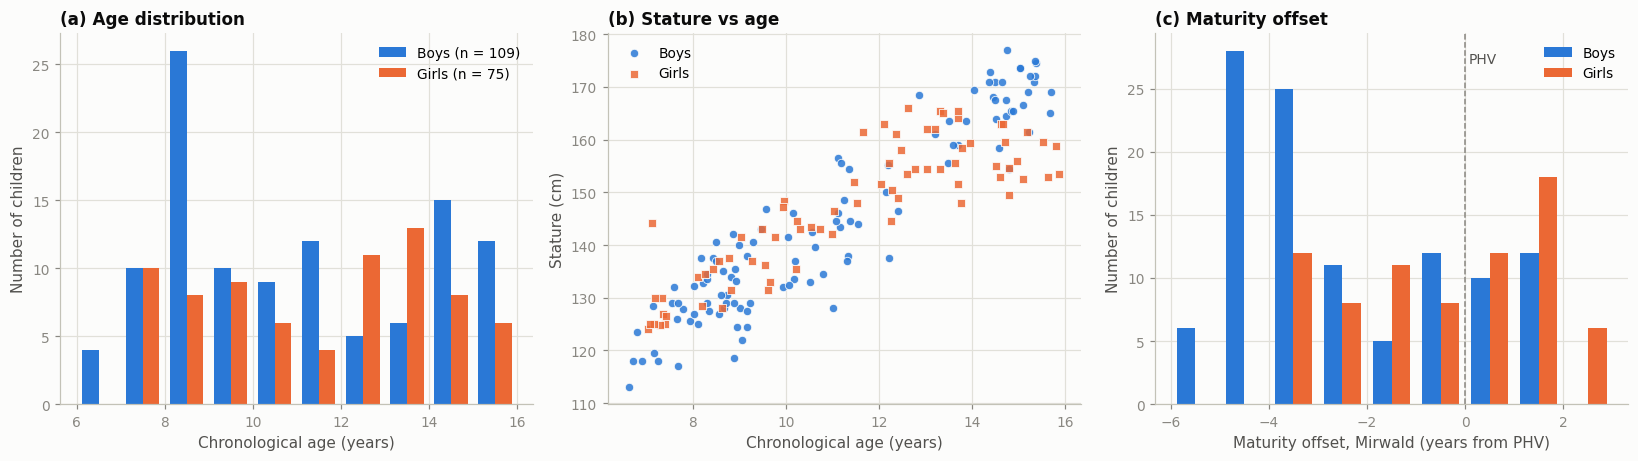

In [ ]:
# ---- Figure 1: sample composition, stature vs age and maturity offset ----
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))

# (a) age distribution, side-by-side bars per 1-year bin
bins = np.arange(6, 17, 1.0)
centers, width = bins[:-1] + 0.5, 0.38
for k, sex in enumerate(["M", "F"]):
    counts, _ = np.histogram(raw.loc[raw["sex"] == sex, "age"], bins=bins)
    axes[0].bar(centers + (k - 0.5) * width, counts, width=width, color=COLORS[sex],
                label=f"{LABELS[sex]} (n = {counts.sum()})")
style_axes(axes[0], "Chronological age (years)", "Number of children", "(a) Age distribution")
axes[0].legend(frameon=False, fontsize=9)

# (b) stature vs age
for sex in ["M", "F"]:
    d = raw[raw["sex"] == sex]
    axes[1].scatter(d["age"], d["stature_cm"], s=30, color=COLORS[sex], marker=MARKERS[sex],
                    alpha=0.85, edgecolor="#fcfcfb", linewidth=0.6, label=LABELS[sex])
style_axes(axes[1], "Chronological age (years)", "Stature (cm)", "(b) Stature vs age")
axes[1].legend(frameon=False, fontsize=9)

# (c) maturity offset distribution
bins_off = np.arange(-6, 4, 1.0)
centers_off = bins_off[:-1] + 0.5
for k, sex in enumerate(["M", "F"]):
    counts, _ = np.histogram(raw.loc[raw["sex"] == sex, "offset_mirwald"], bins=bins_off)
    axes[2].bar(centers_off + (k - 0.5) * width, counts, width=width, color=COLORS[sex], label=LABELS[sex])
axes[2].axvline(0, color=MUTED, linestyle="--", linewidth=1)
axes[2].text(0.08, axes[2].get_ylim()[1] * 0.95, "PHV", color=INK2, fontsize=9, va="top")
style_axes(axes[2], "Maturity offset, Mirwald (years from PHV)", "Number of children",
           "(c) Maturity offset")
axes[2].legend(frameon=False, fontsize=9, loc="upper right")

fig.tight_layout()
plt.show()

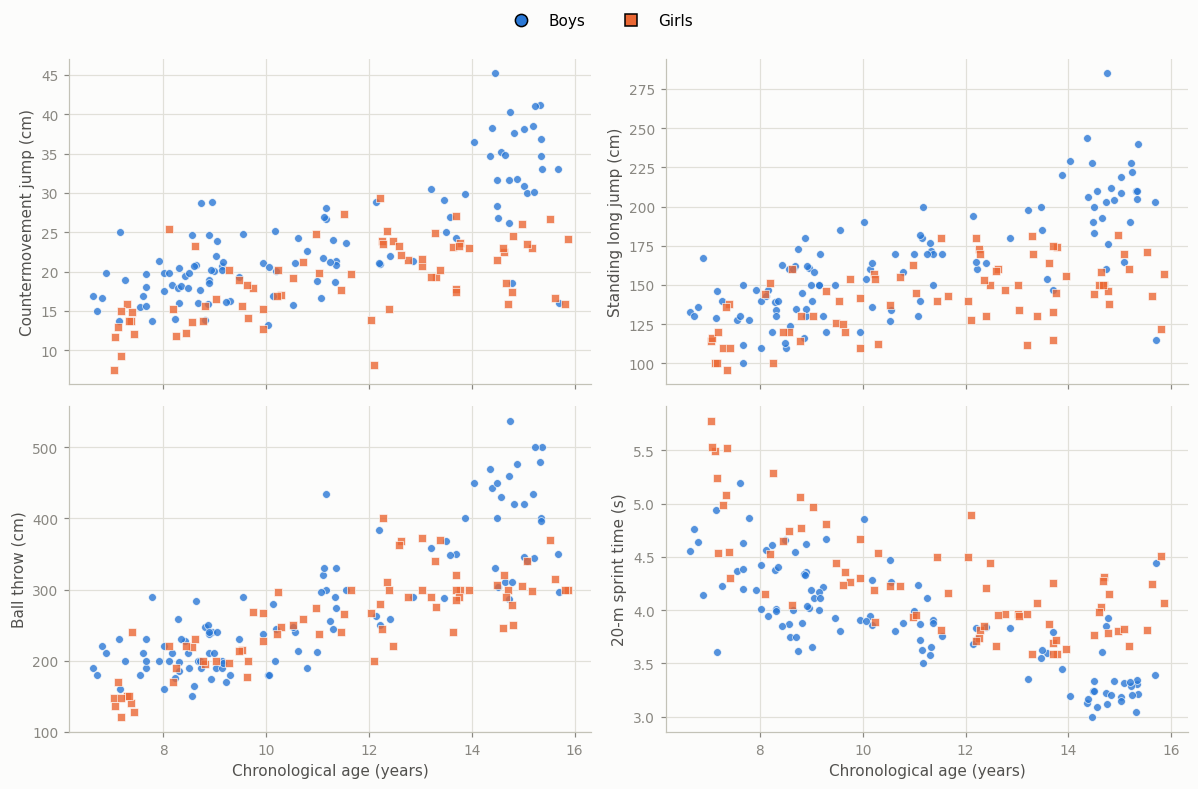

In [ ]:
# ---- Figure 2: four physical tests against chronological age ----
tests = [("cmj_cm", "Countermovement jump (cm)"),
         ("long_jump_cm", "Standing long jump (cm)"),
         ("ball_throw_cm", "Ball throw (cm)"),
         ("sprint_20m_s", "20-m sprint time (s)")]

fig, axes = plt.subplots(2, 2, figsize=(11, 7.2), sharex=True)
for ax, (col, label) in zip(axes.ravel(), tests):
    for sex in ["M", "F"]:
        d = raw[raw["sex"] == sex]
        ax.scatter(d["age"], d[col], s=26, color=COLORS[sex], marker=MARKERS[sex],
                   alpha=0.8, edgecolor="#fcfcfb", linewidth=0.5)
    style_axes(ax, "", label)
for ax in axes[1]:
    ax.set_xlabel("Chronological age (years)", color=INK2)

handles = [Line2D([0], [0], marker=MARKERS[s], color="none", markerfacecolor=COLORS[s],
                  markersize=8, label=LABELS[s]) for s in ["M", "F"]]
fig.legend(handles=handles, loc="upper center", ncol=2, frameon=False)
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

**Reading the figures.** (a) The sample is unbalanced: there are more boys than girls, and some ages have very few children (for example only 4 girls aged 11), a limitation that will matter when we average by age. (b) Stature increases with age in both sexes; girls seem to level off after 13 years while boys keep growing. (c) The Mirwald offset shows that most boys are still *before* PHV (negative values), whereas girls are spread around PHV, as expected because girls reach PHV earlier than boys. In the second figure, performance improves with age in the four tests; the boys' values spread out more in the oldest ages, especially in the ball throw.

# OOP for data processing

### Design of the pipeline

The analysis is organised in **four classes** (the fourth one is defined later, in the matrix section). Each class has one responsibility and they cooperate through *composition* (the analysers receive an `AthleteDataset`) and *inheritance* (all analysers inherit from `BaseAnalyzer`):

| Class | Responsibility | Main methods |
|---|---|---|
| `AthleteDataset` | Holds the data and prepares them (quality checks and preprocessing) | `missingReport`, `rangeCheck`, `flagOutliers`, `imputeMedian`, `addDerivedVariables`, `select` |
| `BaseAnalyzer` | Parent class: keeps a reference to the dataset and checks that the required columns exist | `__init__` |
| `MaturityEstimator` (child) | Computes the Mirwald maturity offset as a matrix product and classifies children as pre-, circa- or post-PHV | `designMatrix`, `offset`, `age_at_phv`, `classify`, `agreement` |
| `ProfileAnalyzer` (child) | Averages a variable in bins and applies numerical differentiation and integration | `binnedProfile`, `forwardDifference`, `centralDifference`, `trapezoid`, `cumulativeTrapezoid` |
| `MatrixAnalyzer` (child, defined in the matrix section) | Standardisation, correlation matrix, eigen-decomposition and PCA | `standardize`, `correlationMatrix`, `eigen`, `scores`, `svdCheck` |

**Preprocessing steps implemented in the classes:** (1) schema and physiological-range checks; (2) detection of outliers with Tukey's IQR rule (values are *flagged*, not deleted, because in a growing sample large values are often real); (3) imputation of missing values with the median of the same sex; (4) derived variables (body mass index and sitting-height ratio); (5) classification of maturity status; (6) standardisation (z-scores), done in the matrix section.

**Mirwald equations.** With $\text{leg}$, $\text{sit}$, $\text{age}$, $\text{mass}$ and $\text{stat}$ (stature) as defined above, the maturity offset (years from PHV) is

- boys: $-9.236 + 0.0002708\,(\text{leg}\cdot\text{sit}) - 0.001663\,(\text{age}\cdot\text{leg}) + 0.007216\,(\text{age}\cdot\text{sit}) + 0.02292\,(100\cdot\text{mass}/\text{stat})$
- girls: $-9.376 + 0.0001882\,(\text{leg}\cdot\text{sit}) + 0.0022\,(\text{age}\cdot\text{leg}) + 0.005841\,(\text{age}\cdot\text{sit}) - 0.002658\,(\text{age}\cdot\text{mass}) + 0.07693\,(100\cdot\text{mass}/\text{stat})$

(Mirwald et al., 2002). Both are written as $\hat y = D\beta$ and implemented in `MaturityEstimator`.

In [ ]:
class AthleteDataset:
    # Container for the anonymised dataset with quality-control and preprocessing helpers.

    # Physiologically plausible ranges used by rangeCheck (children 5-18 years old)
    PLAUSIBLE_RANGES = {
        "age": (5, 18), "stature_cm": (90, 200), "sitting_height_cm": (50, 110),
        "leg_length_cm": (40, 110), "body_mass_kg": (12, 120), "body_fat_pct": (2, 60),
        "sit_and_reach_cm": (-50, 60), "cmj_cm": (5, 60), "long_jump_cm": (60, 320),
        "isometric_force_n": (100, 3500), "ball_throw_cm": (80, 800),
        "sprint_20m_s": (2.5, 7.0), "vo2max": (20, 70),
    }

    def __init__(self, df):
        self._df = df.copy().reset_index(drop=True)     # private copy: the original is never modified

    # ---- basic protocol -------------------------------------------------
    @property
    def data(self):
        return self._df.copy()

    @property
    def columns(self):
        return list(self._df.columns)

    def __len__(self):
        return len(self._df)

    def __repr__(self):
        n_boys = int((self._df["sex"] == "M").sum())
        n_girls = int((self._df["sex"] == "F").sum())
        return f"AthleteDataset(n={len(self)}, boys={n_boys}, girls={n_girls}, columns={len(self.columns)})"

    # ---- quality control ------------------------------------------------
    def missingReport(self):
        counts = self._df.isna().sum()
        report = pd.DataFrame({"n_missing": counts,
                               "pct_missing": (100 * counts / len(self)).round(1)})
        return report[report["n_missing"] > 0]

    def rangeCheck(self):
        # Return a list of (variable, id, value) outside the plausible physiological range.
        # Vectorized: a boolean mask per column, no per-row Python loop (no .iterrows()).
        problems = []
        for col, (low, high) in self.PLAUSIBLE_RANGES.items():
            mask = (self._df[col] < low) | (self._df[col] > high)
            ids = self._df.loc[mask, "id"].astype(int).tolist()
            values = self._df.loc[mask, col].tolist()
            problems.extend(zip([col] * len(ids), ids, values))
        return problems

    def flagOutliers(self, columns, k=1.5):
        # Tukey's rule: values beyond Q1 - k*IQR or Q3 + k*IQR are flagged (NOT removed).
        rows = []
        for col in columns:
            q1, q3 = self._df[col].quantile([0.25, 0.75])
            iqr = q3 - q1
            low, high = q1 - k * iqr, q3 + k * iqr
            rows.append({"variable": col,
                         "lower_fence": round(low, 2), "upper_fence": round(high, 2),
                         "n_below": int((self._df[col] < low).sum()),
                         "n_above": int((self._df[col] > high).sum())})
        return pd.DataFrame(rows).set_index("variable")

    # ---- preprocessing (each method returns a NEW dataset) ----------------
    def imputeMedian(self, columns):
        df = self._df.copy()
        for col in columns:
            df[col] = df[col].fillna(df.groupby("sex")[col].transform("median"))
        return AthleteDataset(df)

    def addDerivedVariables(self):
        df = self._df.copy()
        df["bmi"] = df["body_mass_kg"] / (df["stature_cm"] / 100) ** 2
        df["sitting_height_ratio"] = 100 * df["sitting_height_cm"] / df["stature_cm"]
        return AthleteDataset(df)

    def select(self, sex=None):
        if sex is None:
            return self
        return AthleteDataset(self._df[self._df["sex"] == sex])


class BaseAnalyzer:
    # Parent class of all analysers: stores the dataset and validates the columns it needs.
    required_columns = []

    def __init__(self, dataset):
        if not isinstance(dataset, AthleteDataset):
            raise TypeError("dataset must be an AthleteDataset")
        missing = [c for c in self.required_columns if c not in dataset.columns]
        if missing:
            raise ValueError(f"{type(self).__name__} needs the columns {missing}")
        self.dataset = dataset


class MaturityEstimator(BaseAnalyzer):
    # Maturity offset (years from peak height velocity) with the Mirwald et al. (2002) equations.
    required_columns = ["sex", "age", "stature_cm", "sitting_height_cm", "leg_length_cm", "body_mass_kg"]

    TERMS = ["intercept", "leg x sitting height", "age x leg", "age x sitting height",
             "age x mass", "100 x mass / stature"]
    # Coefficient vectors are stored as explicit 2D column vectors, shape (6, 1) - NOT as rank-1
    # arrays of shape (6,). Per the professor's note in S2_numerical_computation.ipynb ("1D arrays
    # with shape (m,) ... are called rank 1 arrays. THEY SHOULD NOT BE USED"), any vector that takes
    # part in a matrix product is given an explicit 2D shape so the orientation of the product is
    # never ambiguous.
    COEFFICIENTS = {                                   # one coefficient column-vector per sex
        "M": np.array([-9.236, 0.0002708, -0.001663, 0.007216, 0.0, 0.02292]).reshape(-1, 1),
        "F": np.array([-9.376, 0.0001882, 0.0022, 0.005841, -0.002658, 0.07693]).reshape(-1, 1),
    }

    def designMatrix(self):
        # Matrix D (n x 6): one row per child, one column per term of the equation.
        d = self.dataset.data
        return np.column_stack([
            np.ones(len(d)),
            d["leg_length_cm"] * d["sitting_height_cm"],
            d["age"] * d["leg_length_cm"],
            d["age"] * d["sitting_height_cm"],
            d["age"] * d["body_mass_kg"],
            100 * d["body_mass_kg"] / d["stature_cm"],
        ])

    def offset(self):
        # Maturity offset = D @ beta, using the coefficient column-vector of each sex.
        # result is kept as an explicit 2D column (n, 1), not a rank-1 array, while it is pure
        # matrix algebra; it is only flattened with .ravel() at the very end, to build the 1D
        # pandas Series that the rest of the notebook expects.
        d = self.dataset.data
        D = self.designMatrix()
        result = np.full((len(d), 1), np.nan)
        for sex, beta in self.COEFFICIENTS.items():
            mask = (d["sex"] == sex).to_numpy()
            result[mask] = D[mask] @ beta          # (n_sex, 6) @ (6, 1) -> (n_sex, 1)
        return pd.Series(result.ravel(), index=d.index, name="offset_estimated")

    def ageAtPHV(self):
        # Predicted age at PHV = chronological age - maturity offset.
        return self.dataset.data["age"] - self.offset()

    @staticmethod
    def classify(offset, half_width=1.0):
        # pre-PHV: offset < -1 | circa-PHV: -1 to +1 | post-PHV: offset > +1 (years)
        # Vectorized with np.select: no per-child Python loop.
        conditions = [offset < -half_width, offset > half_width]
        choices = ["pre-PHV", "post-PHV"]
        labels = np.select(conditions, choices, default="circa-PHV")
        return pd.Series(labels, index=offset.index, name="maturity_status")

    def agreement(self, reference_column):
        # Compare our offset with a recorded offset column.
        reference = self.dataset.data[reference_column]
        estimate = self.offset()
        diff = estimate - reference
        return {"mean_difference": diff.mean(), "sd_difference": diff.std(),
                "max_abs_difference": diff.abs().max(),
                "pearson_r": float(np.corrcoef(estimate, reference)[0, 1])}


class ProfileAnalyzer(BaseAnalyzer):
    # Binned averages of a variable and numerical differentiation / integration of the profile.
    required_columns = ["sex"]

    def binnedProfile(self, x_col, y_col, width, start, sex=None, min_n=4):
        # Mean of y_col inside consecutive bins of x_col; bins with fewer than min_n children are dropped.
        d = self.dataset.data
        if sex is not None:
            d = d[d["sex"] == sex]
        d = d.dropna(subset=[x_col, y_col])
        rows = []
        for left in np.arange(start, d[x_col].max() + width, width):
            inside = d[(d[x_col] >= left) & (d[x_col] < left + width)]
            if len(inside) >= min_n:
                rows.append({"x": inside[x_col].mean(), "y": inside[y_col].mean(), "n": len(inside)})
        return pd.DataFrame(rows)

    @staticmethod
    def forwardDifference(x, y):
        # Slope between consecutive points, assigned to the left point (first-order accurate).
        x, y = np.asarray(x, float), np.asarray(y, float)
        return x[:-1], (y[1:] - y[:-1]) / (x[1:] - x[:-1])

    @staticmethod
    def centralDifference(x, y, edge_order=1):
        # Central difference at the interior points (second-order accurate, works for unevenly
        # spaced x). At the first and last point only one-sided differences are possible.
        return np.gradient(np.asarray(y, float), np.asarray(x, float), edge_order=edge_order)

    @staticmethod
    def trapezoid(x, y):
        # Integral of y(x) over the whole range with the trapezoidal rule.
        x, y = np.asarray(x, float), np.asarray(y, float)
        return float(np.sum((x[1:] - x[:-1]) * (y[1:] + y[:-1]) / 2))

    @staticmethod
    def cumulativeTrapezoid(x, y):
        # Running integral: value at each x_i of the integral from x_0 to x_i.
        x, y = np.asarray(x, float), np.asarray(y, float)
        steps = (x[1:] - x[:-1]) * (y[1:] + y[:-1]) / 2
        return np.concatenate([[0.0], np.cumsum(steps)])


print("Classes defined:", [c.__name__ for c in (AthleteDataset, BaseAnalyzer, MaturityEstimator, ProfileAnalyzer)])

Classes defined: ['AthleteDataset', 'BaseAnalyzer', 'MaturityEstimator', 'ProfileAnalyzer']


### Notes on style and correctness (from the professor's class notebooks)

The professor's own notebooks (`S1_intro_Python`, `S2_numerical_computation`, `S3_numerical_computation_II`) contain explicit notes on things that **should not** be done. This pipeline follows them on purpose:

- **Naming (S1, PEP8 slide).** *"Methods: lowerCamelCase"* and *"Variables and functions: lowercase_separated_by_underscores"*. So every **method** of a class above is named in camelCase (`missingReport`, `rangeCheck`, `designMatrix`, `binnedProfile`, ...), while plain functions (`style_axes`, `plot_profile_and_rate`, defined earlier/below) and every variable and DataFrame column (`age_phv`, `offset_mirwald`, ...) stay in snake_case, exactly as the same slide asks.
- **Rank-1 arrays (S2, "Note for artificial intelligence").** *"1D arrays with shape (m,) ... are called rank 1 arrays. THEY SHOULD NOT BE USED. Instead, 2D arrays of shape (m,1) or (1,m) are used."* The Mirwald coefficients (`COEFFICIENTS`) are the one place in this notebook where a vector genuinely takes part in a matrix product (`D @ beta`), so they are stored as explicit 2D column vectors of shape `(6, 1)`, never as a bare `(6,)` array; `MaturityEstimator.offset` keeps the result as a 2D column throughout the computation and only flattens it with `.ravel()` at the very end, to build the 1D `pandas.Series` the rest of the notebook expects. Other 1D arrays in this notebook (boolean masks such as `sex_array == "M"`, or vectors such as `offset_mirwald` passed to `np.corrcoef`) are not rewritten as 2D, because they are never used as one side of an ambiguous matrix product — they are boolean filters or plain data vectors handed to library functions that expect exactly 1D input.
- **Vectorization (S2).** *"...replacing `for` loops with linear algebra / array operations... it drastically reduces computation time."* `AthleteDataset.rangeCheck` uses a boolean mask per column (no `.iterrows()`), and `MaturityEstimator.classify` uses `np.select` (no per-child `if/elif`); both were rewritten from an earlier, slower loop-based version for exactly this reason.

### Using the classes: quality control and preprocessing

First we wrap the raw table in an `AthleteDataset` and apply the quality-control methods.

In [ ]:
ds = AthleteDataset(raw)
print(ds)

print("\n1) Missing values:")
display(ds.missingReport())

print("2) Values outside the physiological range (variable, id, value):")
print(ds.rangeCheck())

print("\n3) Outliers by Tukey's rule (1.5 x IQR) - flagged, not removed:")
outlier_columns = ["stature_cm", "body_mass_kg", "body_fat_pct", "sit_and_reach_cm", "cmj_cm",
                   "long_jump_cm", "isometric_force_n", "ball_throw_cm", "sprint_20m_s", "vo2max"]
display(ds.flagOutliers(outlier_columns))

AthleteDataset(n=184, boys=109, girls=75, columns=19)

1) Missing values:


,n_missing,pct_missing
isometric_force_n,1,0.5
sprint_20m_s,3,1.6
rf_thickness_mm,16,8.7
rf_echo_intensity,16,8.7


2) Values outside the physiological range (variable, id, value):
[('sit_and_reach_cm', 151, 77.8)]

3) Outliers by Tukey's rule (1.5 x IQR) - flagged, not removed:


,lower_fence,upper_fence,n_below,n_above
variable,,,,
stature_cm,92.06,199.16,0,0
body_mass_kg,-1.47,78.52,0,0
body_fat_pct,-3.11,40.26,0,0
sit_and_reach_cm,-18.12,25.27,2,1
cmj_cm,5.04,36.69,0,9
long_jump_cm,73.75,229.75,0,3
isometric_force_n,101.77,1839.07,0,8
ball_throw_cm,38.38,469.38,0,6
sprint_20m_s,2.74,5.35,0,4


**Decisions.** The range check flags one value: a sit-and-reach result of 77.8 cm for child `id` 151, which is not plausible for an 11-year-old boy. The IQR rule also flags three boys aged 11 in this test (this one, and two very low values down to −42 cm), so the whole variable should be verified against the original data sheet. Because it is not used in the matrix analysis, I keep it unchanged but flagged. The other flagged values are extremes that belong to the youngest or oldest children: the best jumps, throws and strength values belong to boys aged 12–15, the slowest sprint times to 7-year-old girls and the lowest VO2max to the oldest children. In a growing sample such extremes reflect age, so they are **kept**. Missing values are imputed with the median of the same sex only for the variables that need a complete matrix (next cells).

In [ ]:
# ---- Preprocessing: median imputation by sex + derived variables ----
fitness_columns = ["isometric_force_n", "sprint_20m_s"]
ds_clean = ds.imputeMedian(fitness_columns).addDerivedVariables()

print("Missing values before:", int(ds.data[fitness_columns].isna().sum().sum()),
      "| after:", int(ds_clean.data[fitness_columns].isna().sum().sum()))

# ---- Maturity estimation with the Mirwald equations (matrix product inside the class) ----
estimator = MaturityEstimator(ds_clean)
check_mirwald = estimator.agreement("offset_mirwald")
check_moore = estimator.agreement("offset_moore")

print("\nOur Mirwald offset vs the offset recorded in the study ('offset_mirwald'):")
print({k: float(f"{v:.3g}") for k, v in check_mirwald.items()})
print("\nOur Mirwald offset vs the Moore offset recorded in the study ('offset_moore'):")
print({k: round(float(v), 3) for k, v in check_moore.items()})

# ---- Maturity status and predicted age at PHV ----
status = MaturityEstimator.classify(estimator.offset())
age_phv = estimator.ageAtPHV()
tmp = ds_clean.data.assign(status=status, age_at_phv=age_phv)

print("\nMaturity status by sex (number of children):")
display(pd.crosstab(tmp["sex"].map(LABELS), tmp["status"])[["pre-PHV", "circa-PHV", "post-PHV"]])

print("Predicted age at PHV (years):")
display(tmp.groupby(tmp["sex"].map(LABELS))["age_at_phv"].agg(["count", "mean", "std", "min", "max"]).round(2))

Missing values before: 4 | after: 0

Our Mirwald offset vs the offset recorded in the study ('offset_mirwald'):
{'mean_difference': 7.17e-06, 'sd_difference': 0.000321, 'max_abs_difference': 0.000681, 'pearson_r': 1.0}

Our Mirwald offset vs the Moore offset recorded in the study ('offset_moore'):
{'mean_difference': -0.177, 'sd_difference': 0.292, 'max_abs_difference': 1.177, 'pearson_r': 0.992}

Maturity status by sex (number of children):


status,pre-PHV,circa-PHV,post-PHV
sex,,,
Boys,75,22,12
Girls,31,20,24


Predicted age at PHV (years):


,count,mean,std,min,max
sex,,,,,
Boys,109,13.35,0.82,11.76,15.71
Girls,75,11.93,0.83,9.73,13.75


In [ ]:
# ---- Summary table by sex (mean and standard deviation) ----
summary_cols = ["age", "stature_cm", "body_mass_kg", "bmi", "body_fat_pct", "offset_mirwald",
                "cmj_cm", "long_jump_cm", "ball_throw_cm", "sprint_20m_s", "vo2max"]
g = ds_clean.data.groupby(ds_clean.data["sex"].map(LABELS))[summary_cols]
summary = (g.mean().round(1).astype(str) + " ± " + g.std().round(1).astype(str)).T
display(summary)

sex,Boys,Girls
age,10.9 ± 2.8,11.4 ± 2.7
stature_cm,144.4 ± 17.6,147.1 ± 12.5
body_mass_kg,38.1 ± 13.5,41.9 ± 12.1
bmi,17.6 ± 2.7,19.0 ± 3.4
body_fat_pct,15.5 ± 5.9,24.5 ± 6.3
offset_mirwald,-2.4 ± 2.2,-0.5 ± 2.0
cmj_cm,23.8 ± 7.3,18.9 ± 4.9
long_jump_cm,164.6 ± 34.9,141.7 ± 21.9
ball_throw_cm,279.6 ± 95.1,255.8 ± 65.0
sprint_20m_s,3.9 ± 0.5,4.3 ± 0.5


**Reading the results.** The offset computed by `MaturityEstimator` reproduces the recorded Mirwald offset almost exactly (largest difference below 0.001 years, which is only the rounding to three decimals of the embedded data): the matrix implementation of the equations is therefore correct, and it shows that the study values were computed with exactly these equations. The Moore offset recorded in the study is very strongly correlated with the Mirwald one ($r>0.99$) but is on average higher (less negative) in boys, while in girls both methods practically coincide. Predicted age at PHV is about 13.4 years in boys and 11.9 in girls, in agreement with the well-known two-year gap between the sexes. According to the ±1-year classification, most boys are still pre-PHV, whereas girls are more evenly distributed across the three groups.

# Numerical derivation or integration of data

This section applies **both** numerical differentiation and numerical integration.

*Why differentiate?* Growth velocity is, by definition, the derivative of stature with respect to age, and PHV is the age at which that derivative is maximal. The physical capacities can be treated in the same way: the derivative of a test result with respect to the maturity offset tells us *where in the maturation process* performance increases fastest.

*Important caveat.* Our data are **cross-sectional**: each child is measured only once. Therefore we cannot differentiate the growth curve of one child. What we can do is (1) average stature within age bins, (2) differentiate the resulting mean curve, which gives a *between-group* estimate of growth velocity, and (3) accept that it will be noisy when bins contain few children. The width of the bins is a trade-off: narrow bins give more detail but more noise, wide bins the opposite. I compare 1-year and 2-year bins.

### Step 1. Validating the numerical methods on a function with a known derivative

Before applying the methods to real data, I test them on $f(x)=\sin x$, whose derivative $\cos x$ and integral $\int_0^\pi \sin x\,dx = 2$ are known exactly.

Step h = 0.1571
Max error, forward difference : 0.07838
Max error, central difference : 0.00406
Error of the one-sided difference at the two ends of the range: 0.00411 and 0.00411
Trapezoid integral of sin on [0, pi]: 1.99589  (exact value: 2)


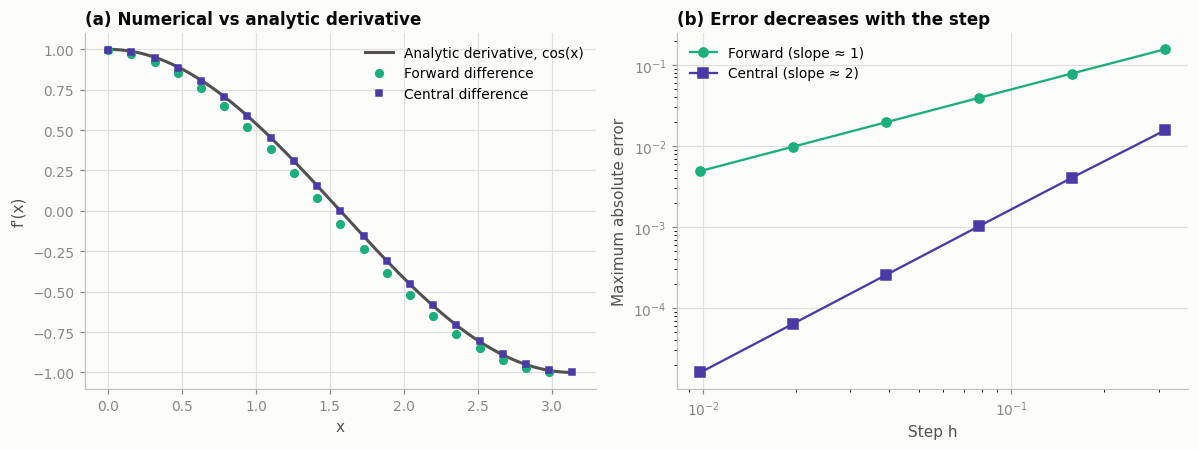

Estimated order of accuracy (slope in log-log): forward = 1.0 | central = 1.99


In [ ]:
# ---- Validation with f(x) = sin(x) ----
x = np.linspace(0, np.pi, 21)
y = np.sin(x)

x_left, forward = ProfileAnalyzer.forwardDifference(x, y)
central = ProfileAnalyzer.centralDifference(x, y)

# Compare both schemes on the same interior points (nodes 1 ... n-2), where the central scheme applies
print(f"Step h = {x[1] - x[0]:.4f}")
print(f"Max error, forward difference : {np.max(np.abs(forward[1:] - np.cos(x_left[1:]))):.5f}")
print(f"Max error, central difference : {np.max(np.abs(central[1:-1] - np.cos(x[1:-1]))):.5f}")
print(f"Error of the one-sided difference at the two ends of the range: "
      f"{abs(central[0] - np.cos(x[0])):.5f} and {abs(central[-1] - np.cos(x[-1])):.5f}")
print(f"Trapezoid integral of sin on [0, pi]: {ProfileAnalyzer.trapezoid(x, y):.5f}  (exact value: 2)")

# Order of accuracy: halve the step several times and record the maximum error
steps, err_fwd, err_cen = [], [], []
for n_points in [11, 21, 41, 81, 161, 321]:
    xs = np.linspace(0, np.pi, n_points)
    ys = np.sin(xs)
    xl, fwd = ProfileAnalyzer.forwardDifference(xs, ys)
    cen = ProfileAnalyzer.centralDifference(xs, ys)
    steps.append(xs[1] - xs[0])
    err_fwd.append(np.max(np.abs(fwd[1:] - np.cos(xl[1:]))))
    err_cen.append(np.max(np.abs(cen[1:-1] - np.cos(xs[1:-1]))))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
xf = np.linspace(0, np.pi, 400)
axes[0].plot(xf, np.cos(xf), color=INK2, linewidth=2, label="Analytic derivative, cos(x)")
axes[0].plot(x_left, forward, "o", color="#1baf7a", markersize=5, label="Forward difference")
axes[0].plot(x, central, "s", color="#4a3aa7", markersize=4, label="Central difference")
style_axes(axes[0], "x", "f'(x)", "(a) Numerical vs analytic derivative")
axes[0].legend(frameon=False, fontsize=9)

axes[1].loglog(steps, err_fwd, "o-", color="#1baf7a", label="Forward (slope ≈ 1)")
axes[1].loglog(steps, err_cen, "s-", color="#4a3aa7", label="Central (slope ≈ 2)")
style_axes(axes[1], "Step h", "Maximum absolute error", "(b) Error decreases with the step")
axes[1].legend(frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

print("Estimated order of accuracy (slope in log-log):",
      "forward =", round(np.polyfit(np.log(steps), np.log(err_fwd), 1)[0], 2),
      "| central =", round(np.polyfit(np.log(steps), np.log(err_cen), 1)[0], 2))

The forward difference has an error that falls in proportion to $h$ (slope ≈ 1), while the central difference falls in proportion to $h^2$ (slope ≈ 2), exactly as the theory predicts, and the trapezoidal rule recovers the integral of $\sin x$ very closely. The methods are therefore correctly implemented. For the real data I use the **central difference** at the interior bins; at the first and last bin only a one-sided difference exists and it is less accurate (the error at the ends printed above), so I will not search for maxima at those two bins.

### Step 2. Growth velocity: derivative of mean stature with respect to age

In [ ]:
# ---- Growth velocity from stature by age bins ----
profiler = ProfileAnalyzer(ds_clean)

age_phv_by_sex = {s: (age_phv[ds_clean.data["sex"] == s].mean(), age_phv[ds_clean.data["sex"] == s].std())
                  for s in ["M", "F"]}

growth = {}                                          # growth[sex][width] -> DataFrame with x, y, n, velocity
for sex in ["M", "F"]:
    growth[sex] = {}
    for width in [2.0, 1.0]:
        prof = profiler.binnedProfile("age", "stature_cm", width=width, start=6.0, sex=sex, min_n=4)
        prof["velocity"] = ProfileAnalyzer.centralDifference(prof["x"], prof["y"])
        growth[sex][width] = prof

for sex in ["M", "F"]:
    print(f"\n{LABELS[sex]} - 2-year age bins (x = mean age, y = mean stature, velocity in cm/year):")
    display(growth[sex][2.0].round(2))


Boys - 2-year age bins (x = mean age, y = mean stature, velocity in cm/year):


,x,y,n,velocity
0,7.32,123.20,14,6.31
1,8.76,132.28,36,5.62
2,10.85,141.93,21,5.62
3,13.01,156.29,11,6.57
4,14.89,168.53,27,6.51



Girls - 2-year age bins (x = mean age, y = mean stature, velocity in cm/year):


,x,y,n,velocity
0,7.24,128.15,10,4.77
1,9.06,136.82,17,4.91
2,10.86,145.95,10,5.18
3,12.98,157.20,24,2.48
4,15.05,156.60,14,-0.29


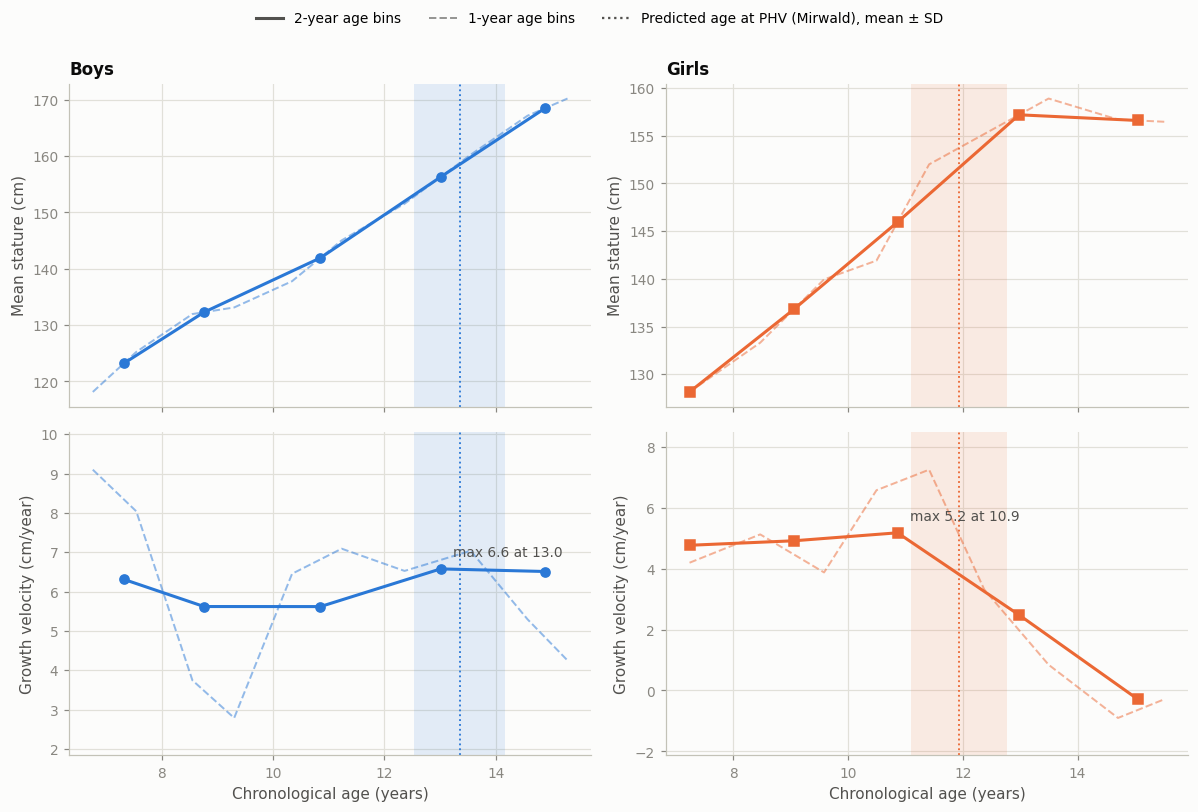

In [ ]:
# ---- Helper to draw "profile + derivative" figures (used again in Step 4) ----
def plot_profile_and_rate(profiles, xlabel, ylabel, ratelabel, main_width, second_width=None,
                          band=None, band_label="", width_label="{} bins"):
    fig, axes = plt.subplots(2, 2, figsize=(11, 7.4), sharex="col")
    for j, sex in enumerate(["M", "F"]):
        for row, key in enumerate(["y", "velocity"]):
            ax = axes[row, j]
            if band is not None:
                mean, sd = band[sex]
                ax.axvspan(mean - sd, mean + sd, color=COLORS[sex], alpha=0.12, linewidth=0)
                ax.axvline(mean, color=COLORS[sex], linestyle=":", linewidth=1.2)
            if second_width is not None:
                p2 = profiles[sex][second_width]
                ax.plot(p2["x"], p2[key], "--", color=COLORS[sex], alpha=0.5, linewidth=1.3)
            p = profiles[sex][main_width]
            ax.plot(p["x"], p[key], "-", marker=MARKERS[sex], color=COLORS[sex], linewidth=2, markersize=6)
            style_axes(ax, "", ylabel if row == 0 else ratelabel,
                       f"{LABELS[sex]}" if row == 0 else "")
            if key == "velocity":
                ax.margins(y=0.15)                                  # headroom for the annotation
                k_max = p["velocity"].iloc[1:-1].idxmax()          # search among interior bins only
                ax.annotate(f"max {p.loc[k_max, 'velocity']:.1f} at {p.loc[k_max, 'x']:.1f}",
                            (p.loc[k_max, "x"], p.loc[k_max, "velocity"]),
                            textcoords="offset points", xytext=(8, 8), fontsize=9, color=INK2)
        axes[1, j].set_xlabel(xlabel, color=INK2)
    handles = [Line2D([0], [0], color=INK2, linewidth=2, label=width_label.format(main_width))]
    if second_width is not None:
        handles.append(Line2D([0], [0], color=INK2, linewidth=1.3, linestyle="--", alpha=0.6,
                              label=width_label.format(second_width)))
    if band is not None:
        handles.append(Line2D([0], [0], color=INK2, linestyle=":", label=band_label))
    fig.legend(handles=handles, loc="upper center", ncol=len(handles), frameon=False, fontsize=9)
    fig.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()


plot_profile_and_rate(growth, "Chronological age (years)", "Mean stature (cm)", "Growth velocity (cm/year)",
                      main_width=2.0, second_width=1.0, band=age_phv_by_sex,
                      band_label="Predicted age at PHV (Mirwald), mean ± SD",
                      width_label="{:g}-year age bins")

In [ ]:
# ---- Where is the maximum of the velocity curve? (2-year bins) ----
for sex in ["M", "F"]:
    p = growth[sex][2.0]
    k = p["velocity"].iloc[1:-1].idxmax()                    # interior bins only
    mean, sd = age_phv_by_sex[sex]
    print(f"{LABELS[sex]:5s}: maximum velocity {p.loc[k, 'velocity']:.1f} cm/year at mean age {p.loc[k, 'x']:.1f} y"
          f"  |  Mirwald predicted age at PHV: {mean:.1f} ± {sd:.1f} y")

Boys : maximum velocity 6.6 cm/year at mean age 13.0 y  |  Mirwald predicted age at PHV: 13.4 ± 0.8 y
Girls: maximum velocity 5.2 cm/year at mean age 10.9 y  |  Mirwald predicted age at PHV: 11.9 ± 0.8 y


### Step 3. Numerical integration: recovering the height gain from the velocity

The fundamental theorem of calculus says that the integral of the velocity between two ages must equal the change in stature. This gives an independent check on the derivative, and it also lets us see *when* the height is gained: the running (cumulative) integral of the velocity curve is the accumulated growth.

,from_age,to_age,observed_gain_cm,integrated_gain_cm,relative_error_%
sex,,,,,
Boys,7.3,14.9,45.33,45.79,1.02
Girls,7.2,15.1,28.45,28.27,-0.62


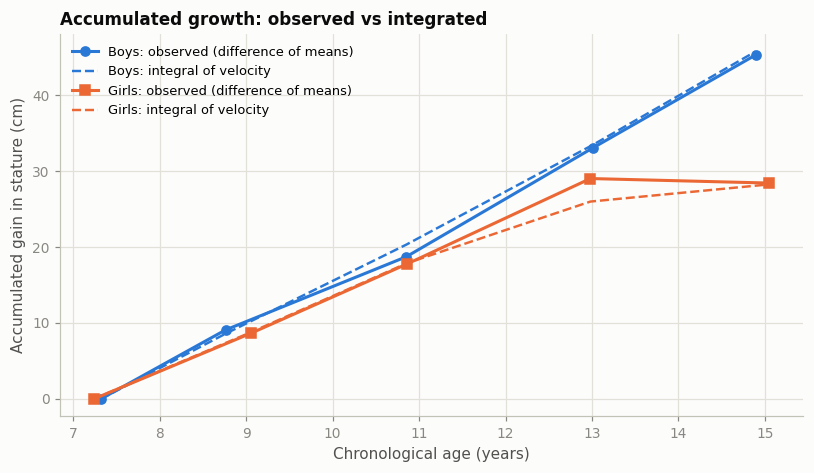

In [ ]:
# ---- Trapezoidal integration of the velocity curve (2-year bins) ----
rows = []
cumulative = {}
for sex in ["M", "F"]:
    p = growth[sex][2.0]
    gain_observed = p["y"].iloc[-1] - p["y"].iloc[0]                       # difference of the mean statures
    gain_integrated = ProfileAnalyzer.trapezoid(p["x"], p["velocity"])    # integral of the velocity
    cumulative[sex] = ProfileAnalyzer.cumulativeTrapezoid(p["x"], p["velocity"])
    rows.append({"sex": LABELS[sex], "from_age": round(p["x"].iloc[0], 1), "to_age": round(p["x"].iloc[-1], 1),
                 "observed_gain_cm": round(gain_observed, 2), "integrated_gain_cm": round(gain_integrated, 2),
                 "relative_error_%": round(100 * (gain_integrated - gain_observed) / gain_observed, 2)})
display(pd.DataFrame(rows).set_index("sex"))

fig, ax = plt.subplots(figsize=(7.5, 4.4))
for sex in ["M", "F"]:
    p = growth[sex][2.0]
    ax.plot(p["x"], p["y"] - p["y"].iloc[0], "-", marker=MARKERS[sex], color=COLORS[sex], linewidth=2,
            label=f"{LABELS[sex]}: observed (difference of means)")
    ax.plot(p["x"], cumulative[sex], "--", color=COLORS[sex], linewidth=1.6,
            label=f"{LABELS[sex]}: integral of velocity")
style_axes(ax, "Chronological age (years)", "Accumulated gain in stature (cm)",
           "Accumulated growth: observed vs integrated")
ax.legend(frameon=False, fontsize=8.5)
fig.tight_layout()
plt.show()

### Step 4. Derivative of physical performance with respect to maturity offset

Now the same tools are applied to performance. Instead of chronological age, the independent variable is the **maturity offset** (years from PHV), averaged in 1-year bins (bins with fewer than 4 children are dropped). The derivative is the average gain in the test *per year of maturation*.

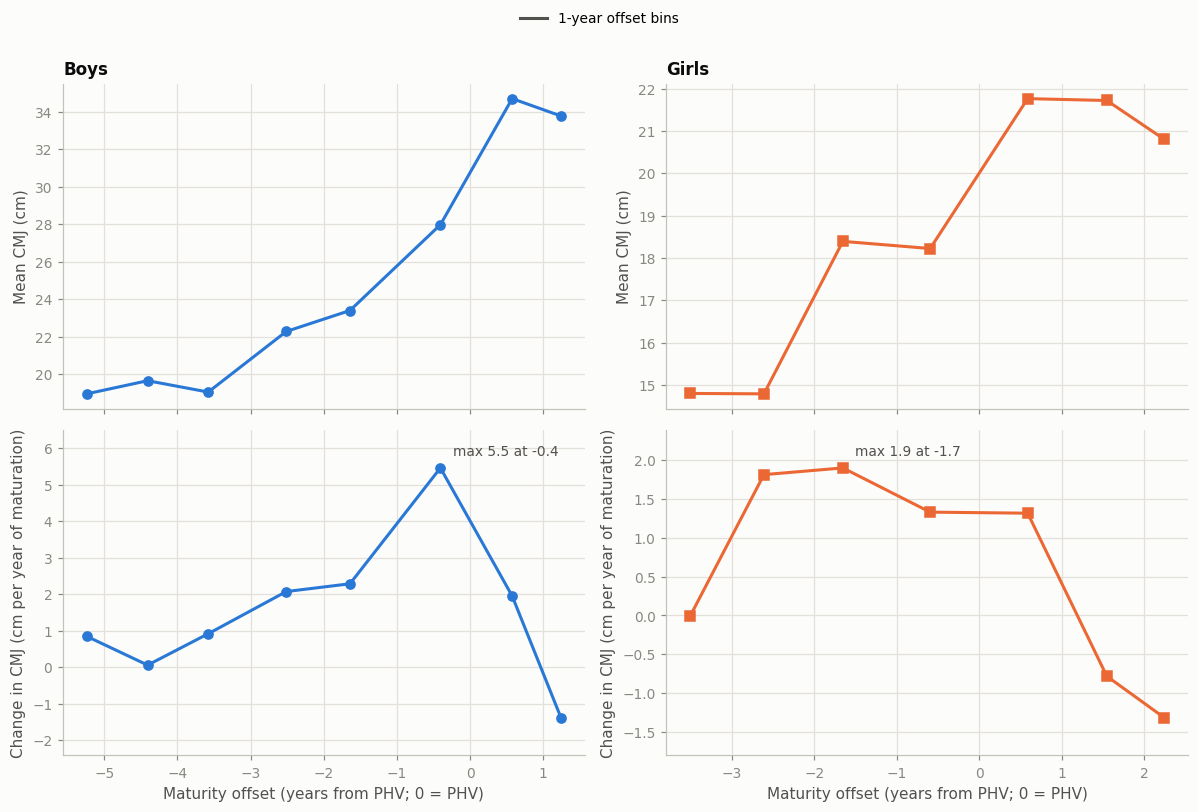

In [ ]:
# ---- Countermovement jump versus maturity offset ----
perf_profiles = {}
for sex in ["M", "F"]:
    prof = profiler.binnedProfile("offset_mirwald", "cmj_cm", width=1.0, start=-6.0, sex=sex, min_n=4)
    prof["velocity"] = ProfileAnalyzer.centralDifference(prof["x"], prof["y"])
    perf_profiles[sex] = {1.0: prof}

plot_profile_and_rate(perf_profiles, "Maturity offset (years from PHV; 0 = PHV)", "Mean CMJ (cm)",
                      "Change in CMJ (cm per year of maturation)", main_width=1.0,
                      width_label="{:g}-year offset bins")

In [ ]:
# ---- Where does each capacity improve fastest? (offset at the maximum rate of improvement, interior bins) ----
tests = {"cmj_cm": +1, "long_jump_cm": +1, "isometric_force_n": +1, "ball_throw_cm": +1,
         "sprint_20m_s": -1}       # for the sprint a decrease in time is an improvement
rows = []
for col, sign in tests.items():
    row = {"test": col}
    for sex in ["M", "F"]:
        p = profiler.binnedProfile("offset_mirwald", col, width=1.0, start=-6.0, sex=sex, min_n=4)
        rate = sign * ProfileAnalyzer.centralDifference(p["x"], p["y"])
        k = 1 + int(np.argmax(rate[1:-1]))                   # interior bins only
        row[f"{LABELS[sex]}: offset of max improvement (y)"] = round(p["x"].iloc[k], 1)
        row[f"{LABELS[sex]}: max improvement per year"] = round(rate[k], 2)
    rows.append(row)
display(pd.DataFrame(rows).set_index("test"))

,Boys: offset of max improvement (y),Boys: max improvement per year,Girls: offset of max improvement (y),Girls: max improvement per year
test,,,,
cmj_cm,-0.4,5.46,-1.7,1.90
long_jump_cm,-0.4,17.21,-1.7,13.63
isometric_force_n,0.6,410.51,-0.6,99.91
ball_throw_cm,0.6,42.49,-2.6,41.10
sprint_20m_s,-0.4,0.20,-1.7,0.36


# Matrix operations

The data are naturally matrices: rows are children and columns are variables. This section applies three families of matrix operations:

1. **Matrix multiplication and slicing:** the Mirwald equations are written explicitly as $D\beta$, using row and column slicing by sex.
2. **Correlation matrix:** built by multiplying the standardised matrix by its transpose, $C = Z^{\top}Z/(n-1)$, and compared between boys and girls with a 3-dimensional array (tensor).
3. **Eigen-decomposition (PCA):** eigenvalues and eigenvectors of $C$ give the main axes of variation of the anthropometric and fitness variables; the result is checked with the singular value decomposition (SVD) and used to build a low-rank approximation of the data.

### Step 1. The Mirwald equations as a matrix product

In [ ]:
# ---- Design matrix, slicing by sex and matrix-vector product ----
D = estimator.designMatrix()                               # matrix n x 6
sex_array = ds_clean.data["sex"].to_numpy()
recorded = ds_clean.data["offset_mirwald"].to_numpy()

print("Design matrix D:", D.shape, "(children x terms)")
print("Terms:", MaturityEstimator.TERMS)
print("\nFirst 3 rows of D (boys and girls mixed):")
print(np.round(D[:3], 3))

for sex in ["M", "F"]:
    rows_sex = sex_array == sex                             # boolean mask -> row slicing
    D_sex = D[rows_sex]                                     # sub-matrix of one sex
    beta = MaturityEstimator.COEFFICIENTS[sex]              # explicit 2D column vector, shape (6, 1)
    y_hat = D_sex @ beta                                    # matrix @ column vector -> (n_sex, 1)
    err = np.max(np.abs(y_hat.ravel() - recorded[rows_sex]))
    print(f"\n{LABELS[sex]}: D is {D_sex.shape}, beta is {beta.shape} (2D, not a rank-1 array), "
          f"D @ beta is {y_hat.shape}; max |D@beta - recorded offset| = {err:.2e} years")

# one child by hand: the matrix product is just a row-by-column dot product
i = int(np.where(sex_array == "M")[0][0])
manual = sum(D[i, j] * MaturityEstimator.COEFFICIENTS["M"][j, 0] for j in range(D.shape[1]))
print(f"\nChild id={int(ds_clean.data.loc[i, 'id'])}: term-by-term sum = {manual:.4f}; recorded offset = {recorded[i]:.4f}")

Design matrix D: (184, 6) (children x terms)
Terms: ['intercept', 'leg x sitting height', 'age x leg', 'age x sitting height', 'age x mass', '100 x mass / stature']

First 3 rows of D (boys and girls mixed):
[[1.000000e+00 4.512640e+03 6.915750e+02 7.595460e+02 2.708040e+02
  1.866200e+01]
 [1.000000e+00 6.266500e+03 1.040012e+03 1.143325e+03 8.650700e+02
  3.962100e+01]
 [1.000000e+00 3.948750e+03 4.482860e+02 5.172530e+02 2.076670e+02
  2.150800e+01]]

Boys: D is (109, 6), beta is (6, 1) (2D, not a rank-1 array), D @ beta is (109, 1); max |D@beta - recorded offset| = 6.39e-04 years

Girls: D is (75, 6), beta is (6, 1) (2D, not a rank-1 array), D @ beta is (75, 1); max |D@beta - recorded offset| = 6.81e-04 years

Child id=1: term-by-term sum = -3.2555; recorded offset = -3.2550


### Step 2. Data matrix, correlation matrix and tensor slicing

I build the matrix $X$ ($n \times 11$) with the anthropometric and fitness variables, standardise it (z-scores) and compute the correlation matrix. `MatrixAnalyzer` is the fourth class of the pipeline; it inherits from `BaseAnalyzer`.

In [ ]:
class MatrixAnalyzer(BaseAnalyzer):
    # Standardisation, correlation matrix, eigen-decomposition (PCA) and SVD check of a data matrix.

    def __init__(self, dataset, columns):
        super().__init__(dataset)
        unknown = [c for c in columns if c not in dataset.columns]
        if unknown:
            raise ValueError(f"unknown columns: {unknown}")
        self.columns = list(columns)
        complete = dataset.imputeMedian(self.columns).data            # no NaN inside the matrix
        self.X = complete[self.columns].to_numpy(dtype=float)          # n x p matrix
        self.sex = complete["sex"].to_numpy()
        self.n, self.p = self.X.shape

    def standardize(self, X=None):
        X = self.X if X is None else X
        return (X - X.mean(axis=0)) / X.std(axis=0, ddof=1)             # z-scores, column by column

    def correlationMatrix(self, X=None):
        Z = self.standardize(X)
        return Z.T @ Z / (len(Z) - 1)                                   # C = Z'Z / (n-1)

    def eigen(self):
        # Eigenvalues (descending) and eigenvectors of the correlation matrix.
        values, vectors = np.linalg.eigh(self.correlationMatrix())     # eigh: for symmetric matrices
        order = np.argsort(values)[::-1]
        values, vectors = values[order], vectors[:, order]
        signs = np.where(vectors[0, :] < 0, -1.0, 1.0)                  # sign convention: first variable > 0
        return values, vectors * signs

    def explainedVarianceRatio(self):
        values, _ = self.eigen()
        return values / values.sum()

    def scores(self, k=2):
        _, V = self.eigen()
        return self.standardize() @ V[:, :k]                            # Z @ V  (projection on k components)

    def svdCheck(self):
        # Eigenvalues must equal s^2/(n-1), where s are the singular values of Z.
        s = np.linalg.svd(self.standardize(), compute_uv=False)
        values, _ = self.eigen()
        return float(np.max(np.abs(s ** 2 / (self.n - 1) - values)))

    def reconstructionError(self, k):
        # Relative Frobenius error of the rank-k approximation of Z.
        Z = self.standardize()
        _, V = self.eigen()
        Z_k = (Z @ V[:, :k]) @ V[:, :k].T
        return float(np.linalg.norm(Z - Z_k) / np.linalg.norm(Z))


PCA_VARS = ["stature_cm", "sitting_height_cm", "leg_length_cm", "body_mass_kg", "body_fat_pct",
            "cmj_cm", "long_jump_cm", "isometric_force_n", "ball_throw_cm", "sprint_20m_s", "vo2max"]
SHORT = ["Stature", "Sitting h.", "Leg length", "Body mass", "Body fat", "CMJ",
         "Long jump", "Isom. force", "Ball throw", "Sprint 20 m", "VO2max"]

ma = MatrixAnalyzer(ds_clean, PCA_VARS)
print("Data matrix X:", ma.X.shape, "| any NaN:", bool(np.isnan(ma.X).any()))

# ---- Slicing: rows (children) by sex, columns (variables) by position ----
boys_rows = ma.sex == "M"
jump_columns = [PCA_VARS.index(c) for c in ["cmj_cm", "long_jump_cm"]]
print("\nMean of the two jump tests, boys :", np.round(ma.X[boys_rows][:, jump_columns].mean(axis=0), 1))
print("Mean of the two jump tests, girls:", np.round(ma.X[~boys_rows][:, jump_columns].mean(axis=0), 1))

# ---- Correlation matrix from the matrix product, checked against numpy ----
C = ma.correlationMatrix()
print("\nMax |C - numpy.corrcoef(X)| =", float(np.max(np.abs(C - np.corrcoef(ma.X, rowvar=False)))))

# ---- Tensor (2 x p x p) with the correlation matrix of each sex and its slices ----
corr_tensor = np.stack([ma.correlationMatrix(ma.X[boys_rows]), ma.correlationMatrix(ma.X[~boys_rows])])
print("Correlation tensor shape (sex, variable, variable):", corr_tensor.shape)
difference = corr_tensor[0] - corr_tensor[1]                                   # boys minus girls
upper = np.triu_indices(len(PCA_VARS), k=1)
top = np.argsort(np.abs(difference[upper]))[::-1][:3]
print("Three pairs whose correlation differs most between boys and girls:")
for t in top:
    a, b = upper[0][t], upper[1][t]
    print(f"  {SHORT[a]} - {SHORT[b]}: boys r = {corr_tensor[0][a, b]:.2f}, girls r = {corr_tensor[1][a, b]:.2f}")

Data matrix X: (184, 11) | any NaN: False

Mean of the two jump tests, boys : [ 23.8 164.6]
Mean of the two jump tests, girls: [ 18.9 141.7]

Max |C - numpy.corrcoef(X)| = 1.2212453270876722e-15
Correlation tensor shape (sex, variable, variable): (2, 11, 11)
Three pairs whose correlation differs most between boys and girls:
  Long jump - Isom. force: boys r = 0.69, girls r = 0.23
  Body mass - Long jump: boys r = 0.64, girls r = 0.18
  Sprint 20 m - VO2max: boys r = 0.17, girls r = 0.58


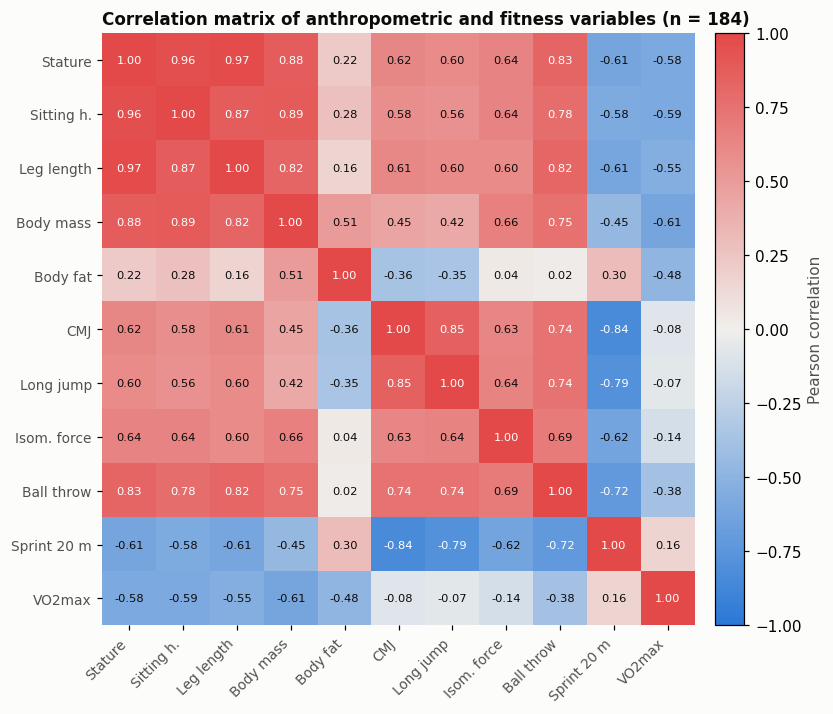

In [ ]:
# ---- Figure: correlation matrix ----
fig, ax = plt.subplots(figsize=(7.6, 6.6))
im = ax.imshow(C, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(SHORT)))
ax.set_yticks(range(len(SHORT)))
ax.set_xticklabels(SHORT, rotation=45, ha="right", fontsize=9, color=INK2)
ax.set_yticklabels(SHORT, fontsize=9, color=INK2)
for i in range(len(SHORT)):
    for j in range(len(SHORT)):
        ax.text(j, i, f"{C[i, j]:.2f}", ha="center", va="center", fontsize=7.5,
                color="white" if abs(C[i, j]) > 0.7 else INK)
for side in ax.spines.values():
    side.set_visible(False)
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
cbar.set_label("Pearson correlation", color=INK2)
ax.set_title("Correlation matrix of anthropometric and fitness variables (n = 184)", loc="left",
             color=INK, fontweight="bold", fontsize=11)
fig.tight_layout()
plt.show()

### Step 3. Eigen-decomposition (principal components)

**Cross-verification (S3_numerical_computation_II).** The professor's third class notebook repeatedly asks to *"compare the result with NumPy"* whenever a linear-algebra result is computed another way (solving a linear system, eigenvalues/eigenvectors with SciPy vs. NumPy). This notebook follows the same practice twice in the matrix section: the correlation matrix built by hand (`Z.T @ Z / (n-1)`) is checked above against `numpy.corrcoef`, and here the eigen-decomposition (`MatrixAnalyzer.eigen`, via `np.linalg.eigh`) is checked against an independent method, the singular value decomposition (`MatrixAnalyzer.svdCheck`, via `np.linalg.svd`) — not against the same function again.

In [ ]:
# ---- Eigenvalues, explained variance, SVD check and low-rank approximation ----
values, V = ma.eigen()
ratio = ma.explainedVarianceRatio()

print("Eigenvalues:", np.round(values, 3))
print("Explained variance (%):", np.round(100 * ratio[:4], 1), "| first 2 components:", round(100 * ratio[:2].sum(), 1), "%")
print("Sum of eigenvalues =", round(values.sum(), 3), "(= number of standardised variables)")
print("\nSVD check, max |s^2/(n-1) - eigenvalue| =", f"{ma.svdCheck():.2e}")
for k in [1, 2, 3]:
    print(f"Rank-{k} approximation: relative reconstruction error = {ma.reconstructionError(k):.3f}")

# ---- Scores and their relation with maturity and age ----
scores = ma.scores(k=2)
offset_vec = ds_clean.data["offset_mirwald"].to_numpy()
age_vec = ds_clean.data["age"].to_numpy()
print("\nCorrelation of PC1 scores with maturity offset:", round(float(np.corrcoef(scores[:, 0], offset_vec)[0, 1]), 2))
print("Correlation of PC1 scores with chronological age:", round(float(np.corrcoef(scores[:, 0], age_vec)[0, 1]), 2))
print("Correlation of PC2 scores with maturity offset:", round(float(np.corrcoef(scores[:, 1], offset_vec)[0, 1]), 2))
for sex in ["M", "F"]:
    m = sex_array == sex
    print(f"Within {LABELS[sex]}: r(PC1, offset) = {np.corrcoef(scores[m, 0], offset_vec[m])[0, 1]:.2f}"
          f" | r(PC1, age) = {np.corrcoef(scores[m, 0], age_vec[m])[0, 1]:.2f}")

loadings = pd.DataFrame(V[:, :3], index=SHORT, columns=["PC1", "PC2", "PC3"]).round(2)
print("\nLoadings (eigenvectors):")
display(loadings)

Eigenvalues: [6.807 2.31  0.636 0.318 0.239 0.21  0.176 0.137 0.108 0.059 0.   ]
Explained variance (%): [61.9 21.   5.8  2.9] | first 2 components: 82.9 %
Sum of eigenvalues = 11.0 (= number of standardised variables)

SVD check, max |s^2/(n-1) - eigenvalue| = 4.44e-15
Rank-1 approximation: relative reconstruction error = 0.617
Rank-2 approximation: relative reconstruction error = 0.414
Rank-3 approximation: relative reconstruction error = 0.337

Correlation of PC1 scores with maturity offset: 0.83
Correlation of PC1 scores with chronological age: 0.9
Correlation of PC2 scores with maturity offset: 0.42
Within Boys: r(PC1, offset) = 0.97 | r(PC1, age) = 0.93
Within Girls: r(PC1, offset) = 0.95 | r(PC1, age) = 0.91

Loadings (eigenvectors):


,PC1,PC2,PC3
Stature,0.36,0.14,0.10
Sitting h.,0.35,0.17,0.03
Leg length,0.35,0.11,0.16
Body mass,0.33,0.28,-0.21
Body fat,0.04,0.59,-0.38
CMJ,0.30,-0.34,0.07
Long jump,0.29,-0.34,0.02
Isom. force,0.30,-0.10,-0.65
Ball throw,0.35,-0.05,-0.01
Sprint 20 m,-0.30,0.30,-0.12


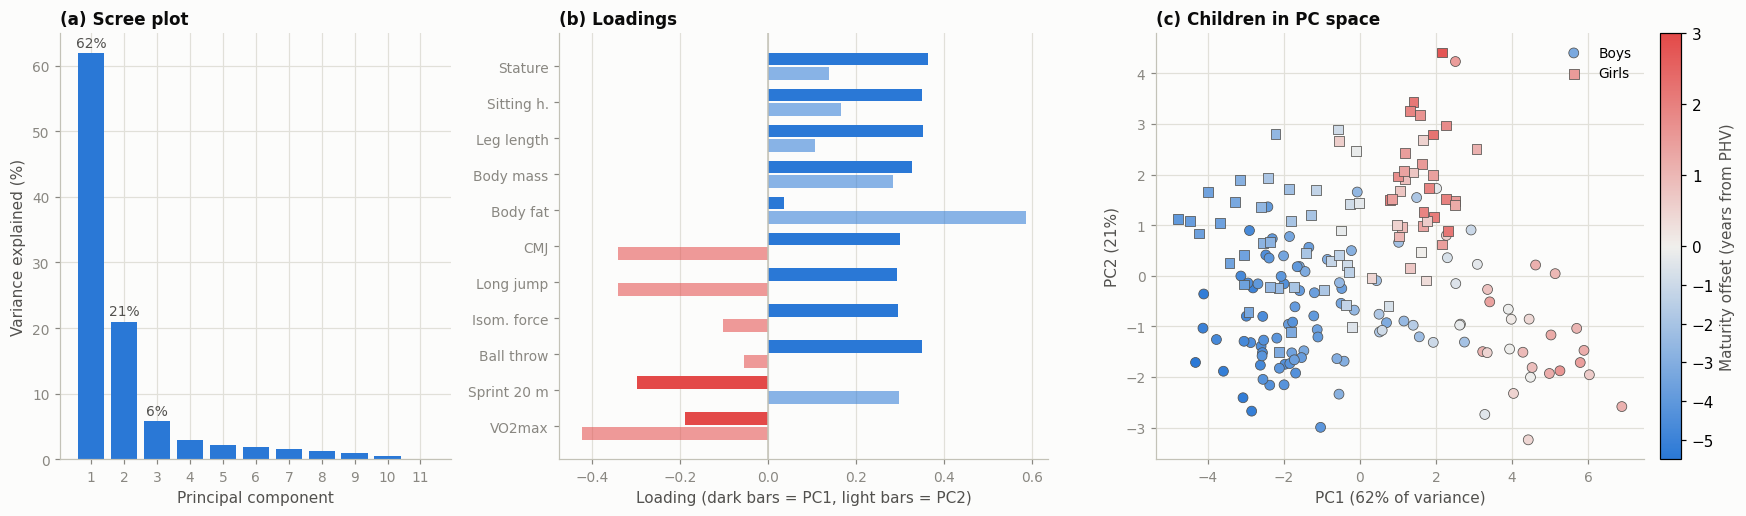

In [ ]:
# ---- Figure: scree plot, loadings and scores ----
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1, 1.25, 1.35]})

# (a) explained variance
axes[0].bar(range(1, len(ratio) + 1), 100 * ratio, color="#2a78d6")
for k in range(3):
    axes[0].text(k + 1, 100 * ratio[k] + 1, f"{100 * ratio[k]:.0f}%", ha="center", fontsize=9, color=INK2)
style_axes(axes[0], "Principal component", "Variance explained (%)", "(a) Scree plot")
axes[0].set_xticks(range(1, len(ratio) + 1))

# (b) loadings of PC1 and PC2
y_pos = np.arange(len(SHORT))
for comp, offset_y, name in [(0, -0.2, "PC1"), (1, 0.2, "PC2")]:
    colors = ["#2a78d6" if v >= 0 else "#e34948" for v in V[:, comp]]
    axes[1].barh(y_pos + offset_y, V[:, comp], height=0.36, color=colors,
                 alpha=1.0 if comp == 0 else 0.55)
axes[1].axvline(0, color=AXIS, linewidth=1)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(SHORT, fontsize=9)
axes[1].invert_yaxis()
style_axes(axes[1], "Loading (dark bars = PC1, light bars = PC2)", "", "(b) Loadings")
axes[1].grid(axis="y", visible=False)

# (c) scores coloured by maturity offset (diverging, zero = PHV), marker by sex
norm = TwoSlopeNorm(vcenter=0, vmin=-5.5, vmax=3.0)
for sex in ["M", "F"]:
    m = sex_array == sex
    sc = axes[2].scatter(scores[m, 0], scores[m, 1], c=offset_vec[m], cmap=DIVERGING, norm=norm, s=42,
                         marker=MARKERS[sex], edgecolor=INK2, linewidth=0.5, label=LABELS[sex])
cb = fig.colorbar(sc, ax=axes[2], fraction=0.046, pad=0.03)
cb.set_label("Maturity offset (years from PHV)", color=INK2)
style_axes(axes[2], f"PC1 ({100 * ratio[0]:.0f}% of variance)", f"PC2 ({100 * ratio[1]:.0f}%)", "(c) Children in PC space")
axes[2].legend(frameon=False, fontsize=9, loc="best")
fig.tight_layout()
plt.show()

**Reading the matrix results.**

- *Matrix multiplication.* Writing the Mirwald equations as $D\beta$ reproduces the recorded offsets for all boys and all girls (differences below 0.001 years, the rounding of the embedded data), and the term-by-term sum for one child equals the matrix result.
- *Correlation matrix.* Stature, sitting height, leg length, body mass and ball throw are strongly and positively correlated with one another: all of them grow together. VO2max (as estimated in this study) and the sprint time move in the opposite direction from the growth variables. The tensor comparison shows that some pairs of variables are correlated differently in boys and in girls.
- *Eigen-decomposition.* The first principal component alone explains about 62% of the total variance and the first two about 83%. PC1 is a *size / development* axis: all growth and strength variables load with the same sign, and sprint time with the opposite sign (a larger PC1 means a bigger, stronger, faster child). PC2 contrasts body composition (body fat, body mass) with aerobic capacity and jumping ability. The SVD check agrees with the eigenvalues, and a rank-2 approximation already captures most of the structure of the standardised data.
- *Relevance to the research question.* Panel (c) shows that the colour gradient (maturity offset) runs along PC1. Within each sex, the PC1 scores are correlated with the offset ($r = 0.97$ in boys, $0.95$ in girls) and, slightly less, with chronological age ($r = 0.93$ and $0.91$). When both sexes are pooled the correlation with the offset is lower ($r = 0.83$) because the offset scale is shifted between boys and girls of the same age. Two cautions are needed: the offset is calculated from stature, sitting height, leg length and body mass, which are four of the eleven variables in the matrix, so part of this relationship is built in; and maturity and age are so closely related that the analysis cannot separate them. Even so, the matrix analysis confirms that growth and maturation are the main source of variation in the physical profile of these children.

# Discussion of results

**Data and preprocessing.** The dataset combines 184 children of both sexes across the whole pubertal range, which is appropriate to study maturation. Quality control found few problems: 4 missing values in the variables used for matrix analysis (imputed with the sex median) and one implausible sit-and-reach value (id 151) that should be checked against the original sheet. Most flagged outliers are legitimate extremes of a growing sample (the best jumps, throws and strength values belong to boys aged 14–15, and the slowest sprint times to 7-year-old girls), so they were kept.

**Maturity estimation.** Writing the Mirwald equations as a matrix product reproduced the maturity offsets recorded in the study (differences below 0.001 years). The predicted age at PHV was 13.4 ± 0.8 years in boys and 11.9 ± 0.8 years in girls, and consequently most boys (75 of 109) were still pre-PHV whereas girls were spread across the three maturity groups. The Moore offset recorded in the study correlated very highly with the Mirwald offset (r = 0.99) but was on average 0.29 years higher in boys, so the choice of equation can change the maturity classification of a boy who is close to the ±1-year limits.

**Growth velocity (numerical derivative).** The numerical methods were validated on a known function (errors decreased with the expected order: 1 for the forward and 2 for the central difference). Applied to the mean stature by age, the central difference gave a velocity curve whose maximum at interior bins was at 13.0 years in boys and 10.9 years in girls, close to the predicted ages at PHV (13.4 and 11.9 years; differences of 0.4 and 1.0 years). However, the evidence is weak: in boys the curve is almost flat (5.6–6.6 cm/year), and with 1-year bins the curves become noisy, especially where a bin has only 4 or 5 children. The velocities (5–7 cm/year) are also lower than the 8–10 cm/year expected at PHV in an individual child (Kemper et al., 2023). This is not an error but a consequence of the data: the mean curve of a group of children who reach PHV at different ages is flatter than the curve of any single child, and the data are cross-sectional, so we are differentiating differences between different children and not the growth of the same child.

**Integration.** Integrating the velocity curve with the trapezoidal rule recovered the observed gain in mean stature within about 1% (boys: 45.8 vs 45.3 cm; girls: 28.3 vs 28.5 cm). This confirms that the derivative and the integral are consistent with each other. The accumulated-growth figure also shows the flattening of girls' stature after about 13 years.

**Performance and maturity.** Differentiating the mean performance with respect to the maturity offset showed that, in boys, the largest yearly improvement in jumping (CMJ, long jump) and sprint time occurred in the bin centred at −0.4 years, that is, close to PHV, while strength and ball throw improved fastest slightly after PHV (+0.6 years). In girls the fastest improvement in jumping and sprint was earlier, about 1.7 years before PHV, and CMJ decreased slightly afterwards. These patterns agree in general with the reported coincidence of best performance and PHV (Philippaerts et al., 2006), but each bin contains only 5–28 children, so they should be considered exploratory.

**Matrix analysis.** The correlation matrix showed that all growth and strength variables move together (for example r = 0.97 between stature and leg length, r = 0.83 between stature and ball throw), and the tensor comparison suggested that some relationships differ between sexes (for example long jump and isometric force: r = 0.69 in boys vs 0.23 in girls; long jump and body mass: 0.64 vs 0.18), possibly related to the higher body fat of girls (24.5% vs 15.5%). The first principal component explained 62% of the variance and the first two 83%. PC1 behaves as a general size/development axis and is strongly related to maturity: within each sex, r = 0.97 (boys) and r = 0.95 (girls) with the maturity offset, and slightly lower with chronological age (0.93 and 0.91). PC2 (21%) contrasts body composition with aerobic capacity and jumping ability.

**Limitations.** (i) The design is cross-sectional and unbalanced, with small bins. (ii) Chronological age and maturity offset are strongly related, and the offset is *calculated* from four of the variables that enter the PCA (stature, sitting height, leg length and body mass), so part of the relationship between PC1 and the offset is built in; the analysis cannot separate the effect of maturity from that of age. (iii) The Mirwald equations have an error of about ±6 months. (iv) The ultrasound variables were only loaded and described in this lab; their relationship with maturity remains to be analysed. (v) Median imputation and the decision to keep outliers are simple choices that could be replaced by more sophisticated methods.

# Conclusions

1. A reproducible, self-contained pipeline was built in Python (four classes with inheritance and composition) to load, check, preprocess and analyse the growth and fitness data of 184 young athletes. The data were anonymised before being embedded in the notebook.
2. The Mirwald maturity offset was implemented as a matrix product and reproduced the values recorded in the study. The predicted age at PHV was about 13.4 years in boys and 11.9 years in girls.
3. The numerical derivative and integral were validated on a known function and then applied to the data. The derivative of the mean stature located the maximum growth velocity near the predicted age at PHV (13.0 vs 13.4 years in boys and 10.9 vs 11.9 years in girls), and the integral of the velocity recovered the observed height gain within about 1%. Because the data are cross-sectional and the bins are small, these results are approximate, and the group velocities are lower than those of individual children.
4. In boys, jumping and sprint improved fastest close to PHV, while strength and throwing improved fastest a little after it; in girls, the fastest improvement was earlier. These are exploratory results that agree with the literature.
5. The eigen-decomposition of the correlation matrix showed that two components explain 83% of the variance of the anthropometric and fitness variables. The first is a size/development axis strongly related to maturity, but maturity cannot be separated from chronological age with these data.
6. Future work: analyse the muscle ultrasound variables together with the maturity offset, compare formally the Mirwald and Moore equations, and repeat the derivative analysis with longitudinal data if follow-up measurements become available.

# AI Use Declaration

AI tool used: Claude (Anthropic).

Purpose: Claude was used as a development assistant to draft the notebook's structure, the Python code (classes, numerical derivative and integral, matrix operations and PCA) and the visualizations, and to explain the code and results to me.

My own contribution: I reviewed the professor's own class notebooks and asked Claude to adapt the code's style to his conventions (vectorization instead of loops, avoiding rank-1 arrays, camelCase method names). I ran every cell, verified the results against my own dataset, and edited part of the explanatory text myself, translating some passages into English with Google Translate.

Extent of AI's contribution: substantial for the first draft of the code and text; the final version reflects my review, corrections and edits.
Not done by AI: the research question, study design, data collection and measurements belong to my research seedbed; the AI did not generate or modify any data value.